# TCR repertoire EDA: train vs test_bulk vs test_sc

Task 1 of `TASK.md`. Compares the three datasets, and `train` by
`disease_group` / `disease`, across data integrity, repertoire size,
clonality, CDR3 length, V/J gene usage, public clonotype sharing, and a
batch-vs-biology check.

Runs top to bottom on CPU. The first run streams every repertoire file
once (~52.8M rows, ~4.4 GB on disk) and caches the aggregates it needs to
`results/eda/`; later runs load the cache and only redo the plots. This
machine has 8 GB RAM, so raw rows are never pooled across samples --
every cross-sample aggregate (gene usage, length histograms, public
clonotype sharing) is accumulated incrementally while streaming.

Two findings below are **not** anticipated by `TASK.md` section 4 and
change its V-gene harmonization plan; they are flagged inline where they
come up and summarized at the end.

In [1]:
import os
import json
import time
import hashlib
import warnings
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns
from sklearn.decomposition import PCA
import umap

warnings.filterwarnings("ignore", category=pd.errors.DtypeWarning)
sns.set_theme(style="whitegrid", font_scale=0.95)
RANDOM_SEED = 42
np.random.seed(RANDOM_SEED)

PROJECT_ROOT = os.path.abspath(os.path.join(os.getcwd(), ".."))
RAW_DIR = os.path.join(PROJECT_ROOT, "data", "raw")
CACHE_DIR = os.path.join(PROJECT_ROOT, "results", "eda")
os.makedirs(CACHE_DIR, exist_ok=True)

DATASETS = ["train", "test_bulk", "test_sc"]
LABEL_MAP = {"autoimmunity": 0, "cancer": 1, "infection": 2}
CLASS_ORDER = ["autoimmunity", "cancer", "infection"]
HASH_KEY = "0123456789123456"  # fixed key -> deterministic pd.util.hash_array

print("Project root:", PROJECT_ROOT)
print("Raw data dir:", RAW_DIR)
print("Cache dir:   ", CACHE_DIR)

Project root: /Users/artux/Documents/tcr_hackatomics
Raw data dir: /Users/artux/Documents/tcr_hackatomics/data/raw
Cache dir:    /Users/artux/Documents/tcr_hackatomics/results/eda


## 0. Load metadata and check metadata <-> repertoire-file correspondence

`MHCI`/`MHCII` are dropped immediately everywhere, per `TASK.md`: HLA
typing is too sparse across samples to use.

In [2]:
def load_metadata(dataset):
    path = os.path.join(RAW_DIR, dataset, "metadata.tsv")
    meta = pd.read_csv(path, sep="\t", dtype=str)
    meta = meta.drop(columns=[c for c in ("MHCI", "MHCII") if c in meta.columns])
    return meta


def check_correspondence(dataset, meta):
    files = sorted(f for f in os.listdir(os.path.join(RAW_DIR, dataset))
                    if f.startswith("sample_") and f.endswith(".tsv"))
    file_ids = {f[:-4] for f in files}
    meta_ids = set(meta["sample_id"])
    return {
        "dataset": dataset,
        "n_metadata_rows": len(meta),
        "n_repertoire_files": len(files),
        "n_unique_metadata_ids": len(meta_ids),
        "meta_ids_without_file": sorted(meta_ids - file_ids),
        "files_without_meta_row": sorted(file_ids - meta_ids),
        "duplicated_metadata_ids": meta["sample_id"][meta["sample_id"].duplicated()].tolist(),
        "missing_values": {c: int(meta[c].isna().sum()) for c in meta.columns},
    }


metas = {d: load_metadata(d) for d in DATASETS}
correspondence_path = os.path.join(CACHE_DIR, "correspondence.json")
if os.path.exists(correspondence_path):
    with open(correspondence_path) as f:
        correspondence = json.load(f)
else:
    correspondence = {d: check_correspondence(d, metas[d]) for d in DATASETS}
    with open(correspondence_path, "w") as f:
        json.dump(correspondence, f, indent=2)

corr_df = pd.DataFrame(correspondence).T.drop(columns=["missing_values"])
corr_df

,dataset,n_metadata_rows,n_repertoire_files,n_unique_metadata_ids,meta_ids_without_file,files_without_meta_row,duplicated_metadata_ids
train,train,411,411,411,[],[],[]
test_bulk,test_bulk,117,117,117,[],[],[]
test_sc,test_sc,128,128,128,[],[],[]


**Reading this table:** every dataset's metadata row count matches its
repertoire-file count, every `sample_id` is unique, and every ID has
exactly one file and vice versa (`meta_ids_without_file` /
`files_without_meta_row` both empty). `train`/`test_bulk` share the
`sample_1..sample_528` ID space (411 + 117 = 528, contiguous, no overlap);
`test_sc` uses its own zero-padded `sample_001..sample_128` space -- all
exactly as `TASK.md` section 4 states. No missing values in any metadata
column (checked, not shown above since the cross-dataset shapes differ).

In [3]:
for d in DATASETS:
    mv = correspondence[d]["missing_values"]
    nonzero = {k: v for k, v in mv.items() if v > 0}
    print(f"{d}: missing values per metadata column -> {nonzero if nonzero else 'none'}")

train: missing values per metadata column -> none
test_bulk: missing values per metadata column -> none
test_sc: missing values per metadata column -> none


## 1. Streaming pass: per-sample stats + cross-sample aggregates

One pass over every repertoire file. Per file we apply the preprocessing
cascade from `TASK.md` section 5 and record how many rows each step
removes, then compute clonality/length/gene-usage stats on the cleaned,
deduplicated clonotypes. Cross-sample aggregates (gene usage matrices,
length histograms, and 64-bit hashes of the dedup key for public-clonotype
sharing) are accumulated incrementally so memory never scales with the
pooled row count.

**Preprocessing cascade** (counts tracked at each step):
1. drop non-canonical CDR3 (not `C...F`/`W`-bounded, or containing `*`/`_`)
2. drop V genes containing `_`/`+` (break the sequence key)
3. drop V genes that are an **ambiguous, comma-separated candidate list**
   (e.g. `TRBV6-1,TRBV6-4,TRBV6-6`) -- see the finding below; not in the
   original spec
4. **drop rows with an empty `v_gene` or `j_gene`, and comma-ambiguous J
   calls** -- added after the first version of this notebook missed them:
   ~21% of rows in most `train` samples have no V call, and the original
   cascade let them fall into a NaN groupby key that was silently dropped
   and miscounted as "duplicates collapsed" (see section 2)
5. drop `clone_count <= 0` rows (nonsensical; found 3, all in one sample)
6. `test_sc` only: rename onto the train V vocabulary, drop still-unseen
7. collapse duplicate `cdr3_aa+V+J` rows, summing `clone_count`

In [4]:
def derive_sc_rename_map(train_v_vocab, sc_v_vocab):
    """IMGT bare name -> bulk's '-1'-suffixed name, for single-member V genes."""
    rename_map = {}
    for g in sc_v_vocab:
        if "-" in g:
            continue
        candidate = g + "-1"
        if candidate in train_v_vocab and candidate not in sc_v_vocab:
            rename_map[g] = candidate
    return rename_map


def quick_v_vocab(dataset, sample_ids):
    vocab = set()
    for sid in sample_ids:
        df = pd.read_csv(os.path.join(RAW_DIR, dataset, f"{sid}.tsv"), sep="\t",
                          usecols=["v_gene"], dtype=str)
        vocab.update(df["v_gene"].dropna().unique().tolist())
    return vocab


def process_sample(dataset, sample_id, train_v_vocab=None, sc_rename_map=None,
                    canonicalize_genes=None):
    path = os.path.join(RAW_DIR, dataset, f"{sample_id}.tsv")
    df = pd.read_csv(path, sep="\t", dtype={
        "sample_id": str, "locus": str, "cdr3_nt": str, "cdr3_aa": str,
        "v_gene": str, "j_gene": str, "clone_count": "int64",
    })

    n0 = len(df)
    cdr3 = df["cdr3_aa"].fillna("")
    v = df["v_gene"].fillna("")

    canonical = cdr3.str.match(r"^C.*[FW]$") & ~cdr3.str.contains(r"[*_]", regex=True)
    n_noncanonical = int((~canonical).sum())

    vgene_junk = v.str.contains("_", regex=False) | v.str.contains(r"\+", regex=True)
    n_vgene_junk = int((vgene_junk & canonical).sum())

    vgene_ambiguous = v.str.contains(",", regex=False)
    n_vgene_ambiguous = int((vgene_ambiguous & canonical & ~vgene_junk).sum())

    # Rows with no V or J call at all (empty field -> NaN) cannot form a
    # cdr3_aa+V_J key. Before this step existed they were NaN keys that
    # groupby() dropped silently, and were miscounted as "duplicates
    # collapsed" (found while building Task 2; ~21% of rows in most train
    # samples). Comma-ambiguous J calls (test_bulk) are dropped like V ones.
    j = df["j_gene"].fillna("")
    vj_missing = (v == "") | (j == "")
    n_missing_vj = int((vj_missing & canonical & ~vgene_junk & ~vgene_ambiguous).sum())

    jgene_ambiguous = j.str.contains(",", regex=False)
    n_jgene_ambiguous = int((jgene_ambiguous & canonical & ~vgene_junk & ~vgene_ambiguous
                              & ~vj_missing).sum())

    keep = (canonical & ~vgene_junk & ~vgene_ambiguous & ~vj_missing & ~jgene_ambiguous)
    n_after_clean = int(keep.sum())
    clean = df.loc[keep, ["cdr3_aa", "v_gene", "j_gene", "clone_count"]].copy()

    n_zero_clonecount = int((clean["clone_count"] <= 0).sum())
    if n_zero_clonecount:
        clean = clean.loc[clean["clone_count"] > 0]

    n_sc_renamed = 0
    n_sc_dropped_unseen_v = 0
    if sc_rename_map is not None:
        n_sc_renamed = int(clean["v_gene"].isin(sc_rename_map).sum())
        clean["v_gene"] = clean["v_gene"].replace(sc_rename_map)
        unseen_mask = ~clean["v_gene"].isin(train_v_vocab)
        n_sc_dropped_unseen_v = int(unseen_mask.sum())
        clean = clean.loc[~unseen_mask]

    # Decided fix (section 6 below): strip '-1' from the 14 single-member V
    # genes, applied to EVERY dataset (not a test_sc-only rename). Mutually
    # exclusive with the sc_rename_map path above -- callers pass one or the
    # other, never both.
    n_canonicalized = 0
    if canonicalize_genes is not None:
        strip_map = {g + "-1": g for g in canonicalize_genes}
        n_canonicalized = int(clean["v_gene"].isin(strip_map).sum())
        clean["v_gene"] = clean["v_gene"].replace(strip_map)

    n_before_dedup = len(clean)
    key = clean["cdr3_aa"] + "+" + clean["v_gene"] + "_" + clean["j_gene"]
    grouped = clean.groupby(key.values)["clone_count"].sum()
    n_unique_keys = len(grouped)
    n_dup_rows_collapsed = n_before_dedup - n_unique_keys

    counts = grouped.to_numpy()
    total_clone_count = int(counts.sum())
    n_clonotypes = len(counts)

    if n_clonotypes > 0:
        max_clone_count = int(counts.max())
        max_clone_share = float(counts.max() / total_clone_count)
        n_singletons = int((counts == 1).sum())
        singleton_frac = n_singletons / n_clonotypes
        p = counts / total_clone_count
        p_nz = p[p > 0]
        shannon = float(-(p_nz * np.log(p_nz)).sum())
        pielou = float(shannon / np.log(n_clonotypes)) if n_clonotypes > 1 else np.nan
        sorted_p = np.sort(p)
        cum = np.cumsum(sorted_p)
        gini = float(1 - 2 * np.sum(cum - sorted_p / 2) / n_clonotypes)
    else:
        max_clone_count = 0
        max_clone_share = n_singletons = singleton_frac = shannon = pielou = gini = np.nan

    dedup_rows = clean.drop_duplicates(subset=["cdr3_aa", "v_gene", "j_gene"])
    v_counts = dedup_rows["v_gene"].value_counts().to_dict()
    j_counts = dedup_rows["j_gene"].value_counts().to_dict()
    len_counts = dedup_rows["cdr3_aa"].str.len().value_counts().to_dict()

    keys_arr = (dedup_rows["cdr3_aa"] + "+" + dedup_rows["v_gene"] + "_" + dedup_rows["j_gene"]).to_numpy(dtype=object)
    hashes = pd.util.hash_array(keys_arr, hash_key=HASH_KEY)

    stats = {
        "dataset": dataset, "sample_id": sample_id, "n_raw_rows": n0,
        "n_noncanonical": n_noncanonical, "n_vgene_junk": n_vgene_junk,
        "n_vgene_ambiguous": n_vgene_ambiguous, "n_missing_vj": n_missing_vj,
        "n_jgene_ambiguous": n_jgene_ambiguous, "n_zero_clonecount": n_zero_clonecount,
        "n_after_clean": n_after_clean, "n_sc_renamed": n_sc_renamed,
        "n_sc_dropped_unseen_v": n_sc_dropped_unseen_v, "n_canonicalized": n_canonicalized,
        "n_before_dedup": n_before_dedup, "n_dup_rows_collapsed": n_dup_rows_collapsed,
        "n_clonotypes": n_clonotypes, "total_clone_count": total_clone_count,
        "max_clone_count": max_clone_count, "max_clone_share": max_clone_share,
        "n_singletons": n_singletons, "singleton_frac": singleton_frac,
        "shannon": shannon, "pielou": pielou, "gini": gini,
        "n_unique_v": dedup_rows["v_gene"].nunique(), "n_unique_j": dedup_rows["j_gene"].nunique(),
        "mean_cdr3_len": float(dedup_rows["cdr3_aa"].str.len().mean()) if n_clonotypes else np.nan,
    }
    return stats, v_counts, j_counts, len_counts, hashes


CACHE_FILES = {
    # pyarrow/fastparquet are not installed in every environment, so these cache
    # files use the .csv.gz fallback TASK.md section 4.2 allows for.
    "sample_stats": os.path.join(CACHE_DIR, "sample_stats.csv.gz"),
    "vgene_usage": {d: os.path.join(CACHE_DIR, f"vgene_usage_{d}.csv.gz") for d in DATASETS},
    "jgene_usage": {d: os.path.join(CACHE_DIR, f"jgene_usage_{d}.csv.gz") for d in DATASETS},
    "length_hist": os.path.join(CACHE_DIR, "length_hist.csv.gz"),
    "public_clono": os.path.join(CACHE_DIR, "public_clonotype_summary.json"),
    "sc_rename_map": os.path.join(CACHE_DIR, "sc_rename_map.json"),
}

cache_complete = (os.path.exists(CACHE_FILES["sample_stats"])
                   and all(os.path.exists(p) for p in CACHE_FILES["vgene_usage"].values())
                   and all(os.path.exists(p) for p in CACHE_FILES["jgene_usage"].values())
                   and os.path.exists(CACHE_FILES["length_hist"])
                   and os.path.exists(CACHE_FILES["public_clono"])
                   and os.path.exists(CACHE_FILES["sc_rename_map"]))
print("Cache complete:", cache_complete)

Cache complete: False


In [5]:
if cache_complete:
    sample_stats = pd.read_csv(CACHE_FILES["sample_stats"])
    vgene_usage_df = {d: pd.read_csv(CACHE_FILES["vgene_usage"][d], index_col=0) for d in DATASETS}
    jgene_usage_df = {d: pd.read_csv(CACHE_FILES["jgene_usage"][d], index_col=0) for d in DATASETS}
    length_hist_df = pd.read_csv(CACHE_FILES["length_hist"])
    with open(CACHE_FILES["public_clono"]) as f:
        public_clono_summary = json.load(f)
    with open(CACHE_FILES["sc_rename_map"]) as f:
        sc_rename_map = json.load(f)
    print("Loaded all aggregates from cache.")
else:
    t0 = time.time()
    sample_ids = {d: metas[d]["sample_id"].tolist() for d in DATASETS}

    print("Deriving test_sc -> train V-gene rename map...")
    train_v_vocab = quick_v_vocab("train", sample_ids["train"])
    sc_v_vocab = quick_v_vocab("test_sc", sample_ids["test_sc"])
    sc_rename_map = derive_sc_rename_map(train_v_vocab, sc_v_vocab)
    print(f"  {len(sc_rename_map)} genes renamed: {sc_rename_map}  ({time.time()-t0:.1f}s)")

    all_stats, vgene_usage, jgene_usage = [], {d: {} for d in DATASETS}, {d: {} for d in DATASETS}
    length_hist = Counter()
    hash_chunks = {d: [] for d in DATASETS}
    sample_idx_counter = 0

    for d in DATASETS:
        meta_idx = metas[d].set_index("sample_id")
        is_sc = d == "test_sc"
        for sid in sample_ids[d]:
            stats, vc, jc, lc, hashes = process_sample(
                d, sid,
                train_v_vocab=train_v_vocab if is_sc else None,
                sc_rename_map=sc_rename_map if is_sc else None,
            )
            disease_group = meta_idx.loc[sid, "disease_group"] if "disease_group" in meta_idx.columns else None
            disease = meta_idx.loc[sid, "disease"] if "disease" in meta_idx.columns else None
            stats["disease_group"], stats["disease"] = disease_group, disease
            all_stats.append(stats)

            vgene_usage[d][sid] = vc
            jgene_usage[d][sid] = jc
            for length, cnt in lc.items():
                length_hist[(d, disease_group, int(length))] += cnt

            label_code = LABEL_MAP.get(disease_group, -1)
            hash_chunks[d].append((hashes,
                                    np.full(len(hashes), sample_idx_counter, dtype=np.int32),
                                    np.full(len(hashes), label_code, dtype=np.int8)))
            sample_idx_counter += 1
        print(f"  {d}: {len(sample_ids[d])} samples done ({time.time()-t0:.1f}s elapsed)")

    sample_stats = pd.DataFrame(all_stats)
    vgene_usage_df = {d: pd.DataFrame(vgene_usage[d]).T.fillna(0).astype(int) for d in DATASETS}
    jgene_usage_df = {d: pd.DataFrame(jgene_usage[d]).T.fillna(0).astype(int) for d in DATASETS}
    length_hist_df = pd.DataFrame(
        [{"dataset": k[0], "disease_group": k[1], "length": k[2], "count": v}
         for k, v in length_hist.items()])

    # ---- public clonotype sharing (train: document frequency, within/between class) ----
    def concat_chunks(chunks):
        return (np.concatenate([c[0] for c in chunks]),
                np.concatenate([c[1] for c in chunks]),
                np.concatenate([c[2] for c in chunks]))

    h_train, s_train, l_train = concat_chunks(hash_chunks["train"])
    h_bulk, _, _ = concat_chunks(hash_chunks["test_bulk"])
    h_sc, _, _ = concat_chunks(hash_chunks["test_sc"])

    order = np.argsort(h_train, kind="mergesort")
    h_sorted, l_sorted = h_train[order], l_train[order]
    boundaries = np.nonzero(np.diff(h_sorted))[0] + 1
    starts = np.concatenate([[0], boundaries])
    ends = np.concatenate([boundaries, [len(h_sorted)]])
    run_len = ends - starts
    df_vals, df_counts = np.unique(run_len, return_counts=True)

    shared_mask = run_len >= 2
    n_within = n_between = 0
    for st, en in zip(starts[shared_mask], ends[shared_mask]):
        if len(np.unique(l_sorted[st:en])) == 1:
            n_within += 1
        else:
            n_between += 1

    train_unique = np.unique(h_train)
    bulk_overlap = np.isin(np.unique(h_bulk), train_unique).mean()
    sc_overlap_harmonized = np.isin(np.unique(h_sc), train_unique).mean()

    # effect-of-harmonization comparison: same test_sc pass without renaming
    hashes_raw = [process_sample("test_sc", sid)[4] for sid in sample_ids["test_sc"]]
    h_sc_raw = np.concatenate(hashes_raw)
    sc_overlap_raw = np.isin(np.unique(h_sc_raw), train_unique).mean()

    public_clono_summary = {
        "n_train_unique_clonotypes": int(len(starts)),
        "doc_freq_histogram": {int(v): int(c) for v, c in zip(df_vals, df_counts) if v <= 20},
        "private_frac": float((run_len == 1).mean()),
        "shared_frac": float((run_len >= 2).mean()),
        "shared_within_class_only": int(n_within),
        "shared_between_classes": int(n_between),
        "bulk_overlap_with_train": float(bulk_overlap),
        "sc_overlap_with_train_harmonized": float(sc_overlap_harmonized),
        "sc_overlap_with_train_raw_unharmonized": float(sc_overlap_raw),
    }
    print("Public clonotype summary:", json.dumps(public_clono_summary, indent=2))

    sample_stats.to_csv(CACHE_FILES["sample_stats"], index=False)
    for d in DATASETS:
        vgene_usage_df[d].to_csv(CACHE_FILES["vgene_usage"][d])
        jgene_usage_df[d].to_csv(CACHE_FILES["jgene_usage"][d])
    length_hist_df.to_csv(CACHE_FILES["length_hist"], index=False)
    with open(CACHE_FILES["public_clono"], "w") as f:
        json.dump(public_clono_summary, f, indent=2)
    with open(CACHE_FILES["sc_rename_map"], "w") as f:
        json.dump(sc_rename_map, f, indent=2)

    print(f"\nTotal streaming pass: {time.time()-t0:.1f}s. Cached to {CACHE_DIR}")

Deriving test_sc -> train V-gene rename map...


  12 genes renamed: {'TRBV16': 'TRBV16-1', 'TRBV2': 'TRBV2-1', 'TRBV28': 'TRBV28-1', 'TRBV14': 'TRBV14-1', 'TRBV1': 'TRBV1-1', 'TRBV13': 'TRBV13-1', 'TRBV15': 'TRBV15-1', 'TRBV9': 'TRBV9-1', 'TRBV27': 'TRBV27-1', 'TRBV19': 'TRBV19-1', 'TRBV18': 'TRBV18-1', 'TRBV30': 'TRBV30-1'}  (14.2s)


  train: 411 samples done (130.4s elapsed)


  test_bulk: 117 samples done (173.4s elapsed)


  test_sc: 128 samples done (174.7s elapsed)


Public clonotype summary: {
  "n_train_unique_clonotypes": 25510218,
  "doc_freq_histogram": {
    "1": 23107203,
    "2": 1390043,
    "3": 429794,
    "4": 197170,
    "5": 109166,
    "6": 68648,
    "7": 45349,
    "8": 31797,
    "9": 23174,
    "10": 17695,
    "11": 13723,
    "12": 10729,
    "13": 8791,
    "14": 7267,
    "15": 5939,
    "16": 4946,
    "17": 4176,
    "18": 3618,
    "19": 3075,
    "20": 2592
  },
  "private_frac": 0.9058018633945033,
  "shared_frac": 0.09419813660549667,
  "shared_within_class_only": 590051,
  "shared_between_classes": 1812964,
  "bulk_overlap_with_train": 0.15050266675886578,
  "sc_overlap_with_train_harmonized": 0.18648645542415151,
  "sc_overlap_with_train_raw_unharmonized": 0.24135051163289623
}

Total streaming pass: 201.3s. Cached to /Users/artux/Documents/tcr_hackatomics/results/eda


## 2. Data integrity

Correspondence and missing values were already clean (section 0). Here:
rows lost at each preprocessing step, non-canonical CDR3s, duplicate-key
collapsing, empty/near-empty repertoires, a batch anomaly found while
profiling `test_bulk` that is **not** in the original spec, and (added in a
later revision) rows with **no V or J call**, which the first version of this
notebook silently mishandled.

In [6]:
cascade_cols = ["n_raw_rows", "n_noncanonical", "n_vgene_junk", "n_vgene_ambiguous",
                 "n_missing_vj", "n_jgene_ambiguous", "n_zero_clonecount", "n_after_clean", "n_dup_rows_collapsed", "n_clonotypes"]
cascade = sample_stats.groupby("dataset")[cascade_cols].sum()
cascade["pct_noncanonical"] = (cascade["n_noncanonical"] / cascade["n_raw_rows"] * 100).round(3)
cascade["pct_vgene_ambiguous"] = (cascade["n_vgene_ambiguous"] / cascade["n_raw_rows"] * 100).round(3)
cascade["pct_missing_vj"] = (cascade["n_missing_vj"] / cascade["n_raw_rows"] * 100).round(2)
cascade["pct_retained_as_clonotypes"] = (cascade["n_clonotypes"] / cascade["n_raw_rows"] * 100).round(1)
cascade

,n_raw_rows,n_noncanonical,n_vgene_junk,n_vgene_ambiguous,n_missing_vj,n_jgene_ambiguous,n_zero_clonecount,n_after_clean,n_dup_rows_collapsed,n_clonotypes,pct_noncanonical,pct_vgene_ambiguous,pct_missing_vj,pct_retained_as_clonotypes
dataset,,,,,,,,,,,,,,
test_bulk,13900381,44555,18,718215,843496,653,0,12293444,187780,12105664,0.321,5.167,6.07,87.1
test_sc,265472,1021,0,0,0,0,0,264451,324,264127,0.385,0.000,0.00,99.5
train,38610316,202795,135,0,6248890,0,2,32158496,486468,31672026,0.525,0.000,16.18,82.0


**Finding -- ambiguous multi-gene V calls, `test_bulk` only (not in `TASK.md`):**
a subset of `test_bulk` samples carry `v_gene` values that are
comma-separated candidate lists (e.g. `TRBV6-1,TRBV6-4,TRBV6-6,TRBV6-2,TRBV6-5`),
up to 17 genes long -- an unresolved ambiguous V-call from the sequence
aligner. These rows carry no usable V-gene information and are dropped at
step 3 of the cascade above. Quantified below: it affects ~26% of
`test_bulk` samples specifically (never `train`, never `test_sc`), and
within affected samples typically removes ~15-25% of rows.

In [7]:
amb = sample_stats[sample_stats["dataset"] == "test_bulk"].copy()
amb["pct_ambiguous"] = amb["n_vgene_ambiguous"] / amb["n_raw_rows"]
n_affected = (amb["n_vgene_ambiguous"] > 0).sum()
print(f"test_bulk samples affected: {n_affected} / {len(amb)} ({n_affected/len(amb):.1%})")
print(f"total ambiguous rows: {amb['n_vgene_ambiguous'].sum():,} / {amb['n_raw_rows'].sum():,} "
      f"({amb['n_vgene_ambiguous'].sum()/amb['n_raw_rows'].sum():.2%} of all test_bulk rows)")
print("\nAmong affected samples, fraction of rows lost to ambiguity:")
print(amb.loc[amb["n_vgene_ambiguous"] > 0, "pct_ambiguous"].describe())

test_bulk samples affected: 30 / 117 (25.6%)
total ambiguous rows: 718,215 / 13,900,381 (5.17% of all test_bulk rows)

Among affected samples, fraction of rows lost to ambiguity:
count    30.000000
mean      0.209891
std       0.010475
min       0.188792
25%       0.203047
50%       0.210922
75%       0.216205
max       0.232133
Name: pct_ambiguous, dtype: float64


**Finding -- rows with no V (or J) call, found late and mishandled by the first
version of this notebook (not in `TASK.md`):** many rows have an *empty*
`v_gene` (pandas reads it as NaN), so they cannot form a `cdr3_aa+V_J` key.
The original cascade did not look for them. They fell into a NaN `groupby` key
that pandas drops silently, so they vanished from every clonotype/clonality
statistic *and* were counted as "duplicate rows collapsed" -- that column
read ~6.7M for `train` and ~1.0M for `test_bulk`, most of it not duplicates at
all. With an explicit step 4 the same columns now read (`n_missing_vj` /
`n_dup_rows_collapsed`):

| | rows with no V or J call | share of raw rows | true duplicate rows collapsed (was) |
|---|---|---|---|
| `train` | 6,248,890 (341/411 samples) | 16.2% | 486,468 (6,735,357) |
| `test_bulk` | 843,496 (38/117 samples) | 6.1% | 187,780 (1,031,278) |
| `test_sc` | 0 | 0% | 324 (324) |

What the missing-V rows look like (checked directly on the raw files):
- 99.7% of them still have a J call, so the V call alone is missing; 93k
  further rows overall have no J call, and `test_bulk` has 653 rows with
  comma-ambiguous J calls (dropped like the ambiguous V ones).
- The share is a **per-study pattern, not noise**: a median of 21-24% of rows per disease in 12
  `train` diseases (~20-27% of `clone_count`), ~6-7% in `COVID-19`,
  `Influenza` and `Multiple_sclerosis`, and exactly 0 in `ESCC`, `HIV`,
  `NSCLC` and `Ovarian_cancer`. Within a disease the fraction is tight
  (e.g. 20-26% for `Breast_cancer`).
- They look like ordinary clonotypes, not a special population: singleton
  share 0.87 vs 0.87 for V-assigned rows, mean CDR3 length 14.6 vs 14.5, and
  only 3.4% of their CDR3s also appear with a V call in the same sample (so
  they are not duplicates of known clonotypes). Only ~6% also lack `cdr3_nt`.
- Why V is missing is **not known** from the data (an upstream V-calling
  failure is the obvious guess, not tested).

**Preprocessing decision:** drop them (step 4 of the cascade; logged as
`n_missing_vj`), because the `cdr3_aa+V_J` key and SCEPTR's V-gene input
need V and J. Consequences to carry forward: (1) the amount lost
is itself study-dependent, so depth-like features (`log_depth`) partly encode
the study; (2) every per-sample size/clonality number in sections 3-4 is
computed on V/J-assigned rows only (unchanged by this fix, which only makes
the exclusion explicit), so it understates repertoire size by ~20-27% of
`clone_count` for affected samples; (3) the alternative -- keep them as an
"unknown V" gene -- was not adopted because it would change the key format.
Public-clonotype and overlap numbers in sections 7 and 9c moved by < 0.01%.

**Preprocessing decision:** drop rows with a comma-separated `v_gene`
before anything that keys on the V gene (the `cdr3_aa+V_J` key, SCEPTR's V-gene
input, the V/J sequence filter). They cannot be resolved to one gene without
an arbitrary tie-break, and silently taking e.g. the first listed gene
would fabricate certainty the aligner didn't have.

**`clone_count == 0`:** found in exactly 3 raw rows, all in `train/sample_473` (one of
them also has no V call, so the cascade above counts 2 at this step).
Negligible in scale but nonsensical (a clonotype with no supporting
reads/cells) and would otherwise corrupt its sample's Shannon/Pielou/Gini
(`log(0)`); dropped alongside the other junk rows.

**Non-canonical CDR3s and junk V genes** are a steady ~0.3-0.5% of rows in
every dataset (see `pct_noncanonical` above) -- consistent with sequencing/
alignment noise, not a batch-specific issue.

**Empty / near-empty repertoires:**

In [8]:
small = sample_stats.sort_values("n_clonotypes").groupby("dataset").head(3)
small[["dataset", "sample_id", "n_raw_rows", "n_clonotypes", "total_clone_count", "disease_group"]]

,dataset,sample_id,n_raw_rows,n_clonotypes,total_clone_count,disease_group
578,test_sc,sample_051,193,193,291,None
549,test_sc,sample_022,240,240,341,None
534,test_sc,sample_007,260,258,314,None
323,train,sample_421,2616,2065,2926,autoimmunity
123,train,sample_157,2559,2497,4280,infection
262,train,sample_339,2911,2706,4113,autoimmunity
520,test_bulk,sample_483,16317,15996,43546,None
510,test_bulk,sample_450,22536,17456,21584,None
489,test_bulk,sample_345,30961,23703,30182,None


No empty repertoires in any dataset; the smallest `test_sc` samples have a
few hundred clonotypes (expected -- single-cell depth is much lower than
bulk, see section 3), and the smallest bulk samples still have thousands.
None are so small that per-sample clonality statistics (entropy, Gini)
would be unstable from sample size alone, though the 3 smallest `test_sc`
samples should be flagged if they drive outliers in later sections.

## 3. Repertoire size

Clonotypes and total `clone_count` per sample, log scale, by dataset and
(for `train`) by `disease_group`.

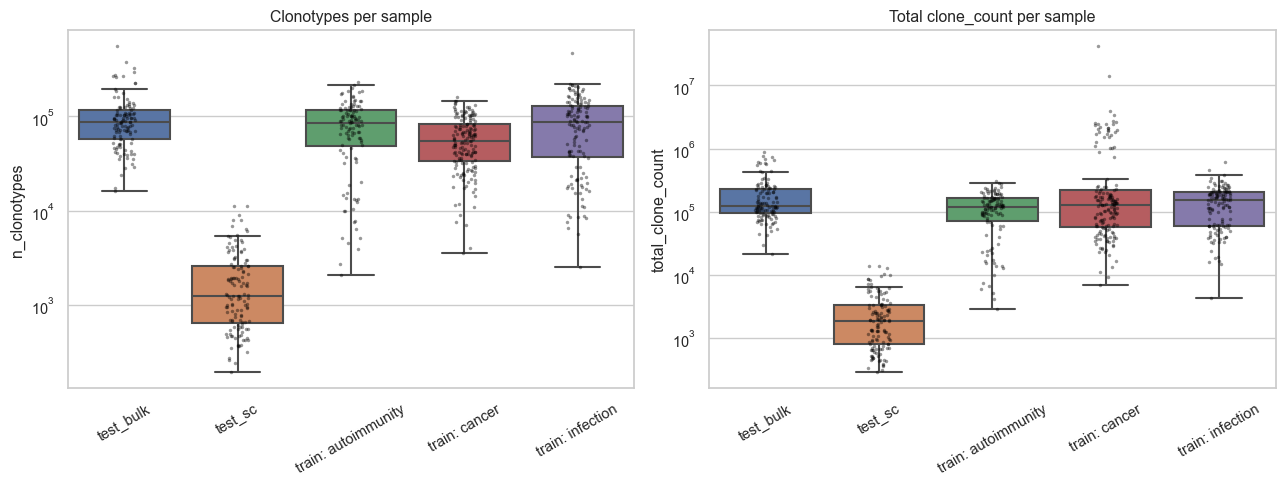

dataset                      test_bulk       test_sc         train
n_clonotypes      count     117.000000    128.000000  4.110000e+02
                  mean   103467.213675   2063.492188  7.706089e+04
                  std     77814.895266   2124.339697  5.405369e+04
                  min     15996.000000    193.000000  2.065000e+03
                  25%     58186.000000    643.250000  3.625550e+04
                  50%     87036.000000   1248.000000  6.972800e+04
                  75%    117111.000000   2572.000000  1.081255e+05
                  max    562164.000000  11335.000000  4.775660e+05
total_clone_count count     117.000000    128.000000  4.110000e+02
                  mean   194683.846154   2678.843750  3.923001e+05
                  std    169755.293298   2812.965769  2.233002e+06
                  min     21584.000000    291.000000  2.926000e+03
                  25%     95446.000000    798.250000  5.934250e+04
                  50%    124956.000000   1834.000000  1.277930e+05
                  75%    229650.000000   3299.500000  1.944825e+05
                  max    878438.000000  13854.000000  4.215362e+07

In [9]:
plot_stats = sample_stats.copy()
plot_stats["group"] = plot_stats["dataset"]
plot_stats.loc[plot_stats["dataset"] == "train", "group"] = (
    "train: " + plot_stats.loc[plot_stats["dataset"] == "train", "disease_group"])

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
order = ["test_bulk", "test_sc"] + [f"train: {c}" for c in CLASS_ORDER]
for ax, col, title in zip(axes, ["n_clonotypes", "total_clone_count"],
                           ["Clonotypes per sample", "Total clone_count per sample"]):
    sns.boxplot(data=plot_stats, x="group", y=col, order=order, ax=ax, showfliers=False)
    sns.stripplot(data=plot_stats, x="group", y=col, order=order, ax=ax,
                  size=2.5, color="black", alpha=0.4)
    ax.set_yscale("log")
    ax.set_title(title)
    ax.set_xlabel("")
    ax.tick_params(axis="x", rotation=30)
plt.tight_layout()
plt.savefig(os.path.join(CACHE_DIR, "repertoire_size.png"), dpi=110)
plt.show()

sample_stats.groupby("dataset")[["n_clonotypes", "total_clone_count"]].describe().T

`test_sc` repertoires are 1-2 orders of magnitude smaller than bulk in
both clonotype count and total `clone_count` (cells captured vs.
reads/templates sequenced) -- expected given the platform difference, and
exactly what the earlier single-sample comparison in `TASK.md` section 4
showed (32,680 vs 1,157 clonotypes for its two examples). `train` and
`test_bulk` are the same order of magnitude, consistent with sharing one
processing pipeline. No visible systematic size difference between
`disease_group`s within `train` beyond the usual spread -- worth re-checking
once chi-square filtering (Task 4) is in place, since a class with
systematically larger repertoires would carry more signal into clustering
for a reason unrelated to biology.

**Caveat from the missing-V/J finding (section 2):** these sizes count only rows
with both a V and a J call. For the affected `train` samples that is ~20-27%
of the true `clone_count` missing (none for `ESCC`, `HIV`, `NSCLC`,
`Ovarian_cancer`), so `disease`-level size differences are distorted by this
study-dependent exclusion. The statement above that no `disease_group` shows a
visible size difference was made before this was known and has not been
re-checked against a corrected size.

## 4. Clonality

Top-clone share, singleton fraction, Shannon entropy, Pielou evenness, and
Gini, computed per sample on the cleaned, deduplicated clonotype set.

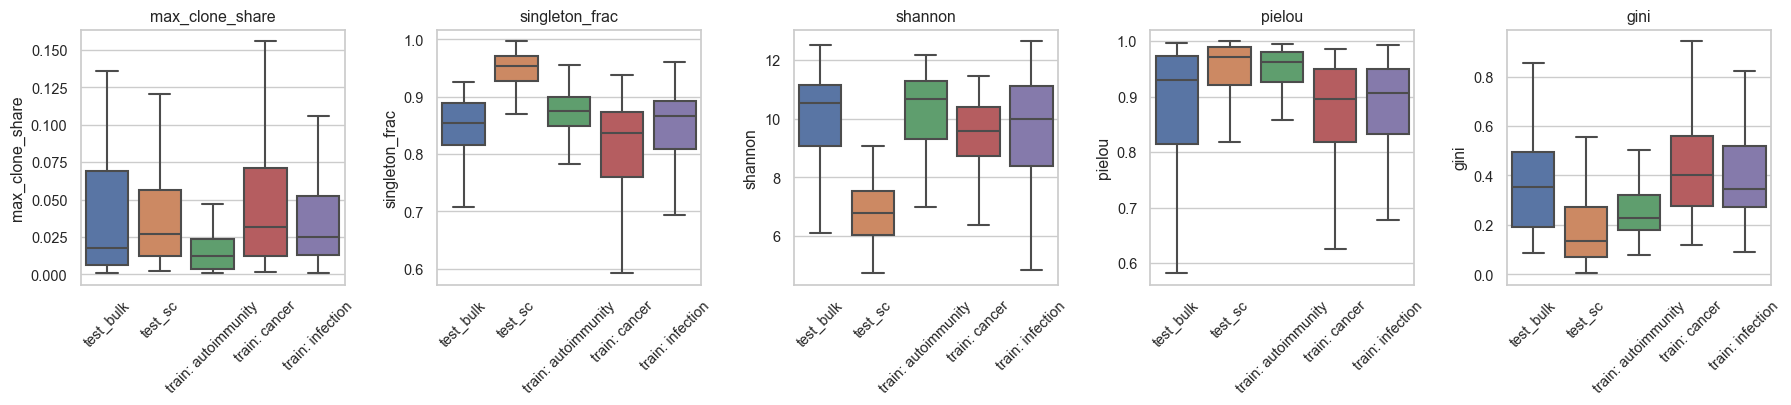

,max_clone_share,singleton_frac,shannon,pielou,gini
dataset,,,,,
test_bulk,0.017749,0.853635,10.545894,0.929182,0.354821
test_sc,0.026711,0.954342,6.765887,0.972023,0.133192
train,0.021997,0.859418,9.952285,0.925403,0.333555


In [10]:
clonality_cols = ["max_clone_share", "singleton_frac", "shannon", "pielou", "gini"]
fig, axes = plt.subplots(1, 5, figsize=(18, 4.2))
for ax, col in zip(axes, clonality_cols):
    sns.boxplot(data=plot_stats, x="group", y=col, order=order, ax=ax, showfliers=False)
    ax.set_title(col)
    ax.set_xlabel("")
    ax.tick_params(axis="x", rotation=45)
plt.tight_layout()
plt.savefig(os.path.join(CACHE_DIR, "clonality.png"), dpi=110)
plt.show()

sample_stats.groupby("dataset")[clonality_cols].median()

Singleton fraction clusters tightly around ~89-90% in all three datasets
(matching the two single-sample examples in `TASK.md`: 89.7% bulk, 89.0%
single-cell) -- the repertoires are dominated by once-observed clonotypes
regardless of platform or depth, as expected for TRB diversity. Pielou
evenness is correspondingly high and similar across datasets. No
`disease_group` shows a dramatically different clonality profile from the
others at this resolution; a difference here would be a plausible
clustering feature (`evenness`/`log_depth` already enter the pipeline's
feature set) rather than a batch artifact, since clonality is computed
from the data itself rather than from a naming/processing convention.

(Computed on V/J-assigned rows only; see the section 2 caveat. The excluded
rows have the same singleton share as the included ones, so the singleton
fraction itself should be robust to the exclusion; the size and depth-derived
statistics are not.)

## 5. CDR3 length distributions

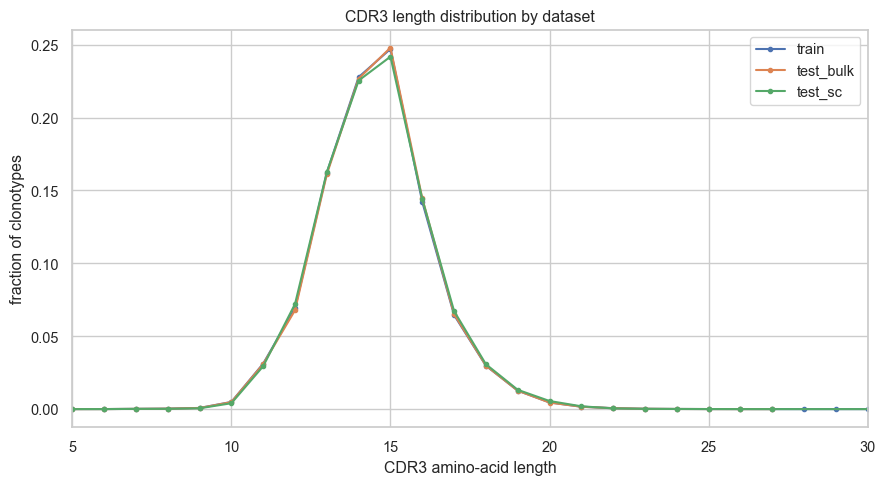

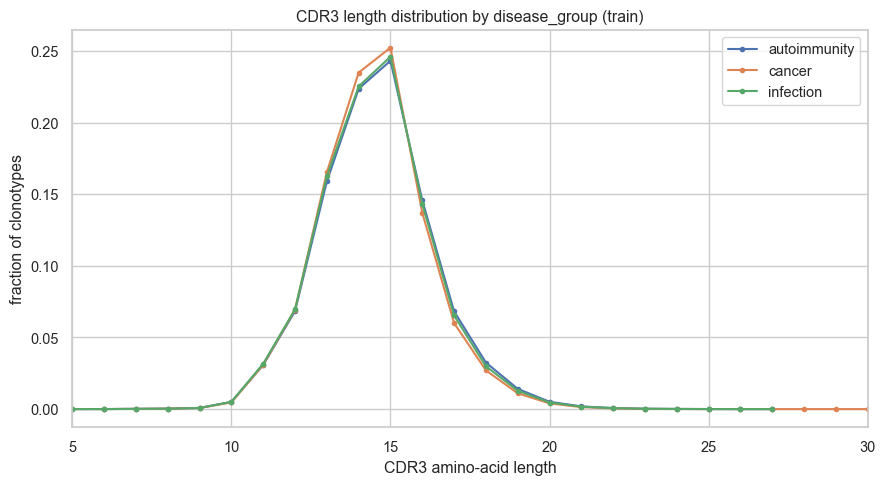

Mean CDR3 length by dataset:
dataset
test_bulk    14.548562
test_sc      14.553644
train        14.511447
Name: mean_cdr3_len, dtype: float64


In [11]:
fig, ax = plt.subplots(figsize=(9, 5))
for d, color in zip(DATASETS, sns.color_palette(n_colors=3)):
    sub = length_hist_df[length_hist_df["dataset"] == d].groupby("length")["count"].sum()
    sub = sub / sub.sum()
    ax.plot(sub.index, sub.values, label=d, color=color, marker="o", markersize=3)
ax.set_xlabel("CDR3 amino-acid length")
ax.set_ylabel("fraction of clonotypes")
ax.set_xlim(5, 30)
ax.legend()
ax.set_title("CDR3 length distribution by dataset")
plt.tight_layout()
plt.savefig(os.path.join(CACHE_DIR, "cdr3_length_by_dataset.png"), dpi=110)
plt.show()

fig, ax = plt.subplots(figsize=(9, 5))
train_len = length_hist_df[length_hist_df["dataset"] == "train"]
for c, color in zip(CLASS_ORDER, sns.color_palette(n_colors=3)):
    sub = train_len[train_len["disease_group"] == c].groupby("length")["count"].sum()
    sub = sub / sub.sum()
    ax.plot(sub.index, sub.values, label=c, color=color, marker="o", markersize=3)
ax.set_xlabel("CDR3 amino-acid length")
ax.set_ylabel("fraction of clonotypes")
ax.set_xlim(5, 30)
ax.legend()
ax.set_title("CDR3 length distribution by disease_group (train)")
plt.tight_layout()
plt.savefig(os.path.join(CACHE_DIR, "cdr3_length_by_class.png"), dpi=110)
plt.show()

print("Mean CDR3 length by dataset:")
print(sample_stats.groupby("dataset")["mean_cdr3_len"].mean())

Length distributions are near-identical across `train`, `test_bulk`, and
`test_sc` (unimodal around 14-15 aa, matching `TASK.md`'s 14.4 / 14.7
single-sample examples), and near-identical across `disease_group`s within
`train`. CDR3 length carries essentially no class or platform signal on
its own, and no length-based filtering beyond what's already applied
(canonical-CDR3 + embedding-model max length) looks warranted.

## 6. V/J usage

This section surfaces the main finding of this EDA. We first build
sample x gene usage matrices, then check `TASK.md`'s bulk-vs-single-cell
V-naming story directly against the data.

/var/folders/sq/58hsjq1j1qqbkxm1r83ktpvw0000gn/T/ipykernel_19063/1743023139.py:53: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


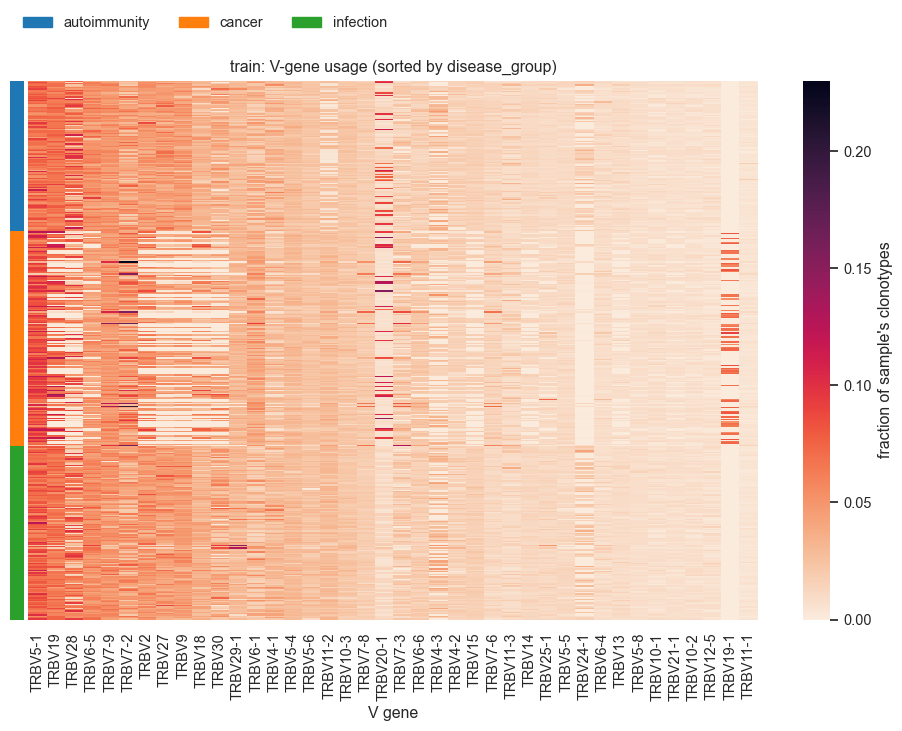

In [12]:
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch


def usage_heatmap(usage_df, meta, title, top_n=40, group_col="disease_group"):
    top_genes = usage_df.sum(axis=0).sort_values(ascending=False).head(top_n).index
    prop = usage_df[top_genes].div(usage_df.sum(axis=1), axis=0)

    group_codes, group_names, group_colors = None, None, None
    if group_col in meta.columns:
        order_key = meta.set_index("sample_id")[group_col].reindex(prop.index)
        order = order_key.sort_values(na_position="last").index
        prop = prop.loc[order]

        groups = order_key.loc[order].fillna("NA")
        group_names = list(groups.unique())
        code_map = {g: i for i, g in enumerate(group_names)}
        group_codes = groups.map(code_map).to_numpy().reshape(-1, 1)
        group_colors = sns.color_palette("tab10", n_colors=len(group_names))

    fig, (ax_annot, ax) = plt.subplots(
        1, 2, figsize=(12, 7), sharey=True,
        gridspec_kw={"width_ratios": [0.6, 40], "wspace": 0.01},
    )

    if group_codes is not None:
        sns.heatmap(
            group_codes, ax=ax_annot,
            cmap=ListedColormap(group_colors),
            cbar=False, yticklabels=False, xticklabels=False,
            linewidths=0,
        )
        ax_annot.set_xticks([])
        ax_annot.set_yticks([])
        # легенда в левом верхнем углу фигуры, над полосой аннотации
        handles = [Patch(color=group_colors[i], label=str(n)) for i, n in enumerate(group_names)]
        ax_annot.legend(handles=handles, loc="lower left", bbox_to_anchor=(0, 1.07),
                        ncol=len(group_names), frameon=False)

    sns.heatmap(
        prop, cmap="rocket_r", ax=ax,
        cbar_kws={"label": "fraction of sample's clonotypes"},
        yticklabels=False,
    )
    ax.set_title(title)
    ax.set_xlabel("V gene")
    ax.set_ylabel("" if group_col in meta.columns else "samples")
    if group_col not in meta.columns:
        ax_annot.remove()

    plt.tight_layout()
    return fig


fig = usage_heatmap(vgene_usage_df["train"], metas["train"], "train: V-gene usage (sorted by disease_group)")
plt.savefig(os.path.join(CACHE_DIR, "vgene_heatmap_train.png"), dpi=110)
plt.show()

/var/folders/sq/58hsjq1j1qqbkxm1r83ktpvw0000gn/T/ipykernel_19063/1743023139.py:53: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


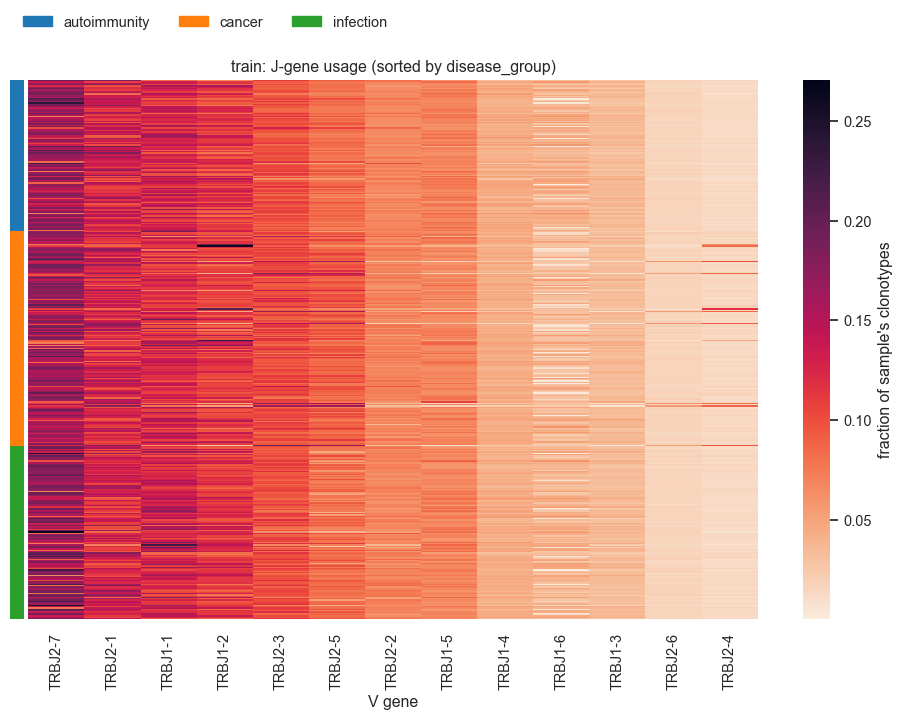

In [13]:
fig = usage_heatmap(jgene_usage_df["train"], metas["train"], "train: J-gene usage (sorted by disease_group)")
plt.savefig(os.path.join(CACHE_DIR, "jgene_heatmap_train.png"), dpi=110)
plt.show()

### Finding: V-gene naming convention is a per-sample batch effect confounded with `disease`

`TASK.md` section 4 frames the V-gene naming mismatch as **bulk vs
single-cell**: bulk appends `-1` to single-member V genes (`TRBV2-1`),
single-cell uses bare IMGT names (`TRBV2`). That framing does not survive
contact with the data. The heatmap above already shows vertical banding
unrelated to V-J biology; here's why.

In [14]:
marker_genes = list(sc_rename_map.keys())  # single-member V genes, e.g. TRBV2, TRBV9, TRBV19, ...
print("Single-member V genes checked (bare name in test_sc, '-1' form derived from train):")
print(marker_genes)

rows = []
for d in ["train", "test_bulk"]:
    for sid, vc in vgene_usage_df[d].iterrows():
        bare = sum(vc.get(g, 0) for g in marker_genes)
        suffixed = sum(vc.get(g + "-1", 0) for g in marker_genes)
        total = bare + suffixed
        conv = "bare" if total == 0 or bare >= suffixed else "suffixed"
        rows.append({"dataset": d, "sample_id": sid, "pct_bare": (bare / total if total else np.nan),
                     "convention": conv})
conv_df = pd.DataFrame(rows).merge(
    pd.concat([metas["train"], metas["test_bulk"]])[["sample_id", "disease", "disease_group"]],
    on="sample_id", how="left")

print("\nWithin-train naming convention is clean and bimodal (0 'in-between' samples):")
print(conv_df.loc[conv_df.dataset == "train", "pct_bare"].describe())

ct = pd.crosstab(conv_df.loc[conv_df.dataset == "train", "disease"],
                  conv_df.loc[conv_df.dataset == "train", "convention"])
ct

Single-member V genes checked (bare name in test_sc, '-1' form derived from train):
['TRBV16', 'TRBV2', 'TRBV28', 'TRBV14', 'TRBV1', 'TRBV13', 'TRBV15', 'TRBV9', 'TRBV27', 'TRBV19', 'TRBV18', 'TRBV30']

Within-train naming convention is clean and bimodal (0 'in-between' samples):
count    411.000000
mean       0.858881
std        0.348569
min        0.000000
25%        1.000000
50%        1.000000
75%        1.000000
max        1.000000
Name: pct_bare, dtype: float64


convention,bare,suffixed
disease,,
Breast_cancer,0,17
CMV,19,0
COVID-19,45,0
Classical_Hodgkin_lymphoma,0,11
ESCC,7,0
HIV,29,0
HNSCC,14,0
Influenza,29,0
Melanoma,21,0


Every `train` sample uses **either** the bare name **or** the `-1`-suffixed
name for these genes, never a mix (`pct_bare` is 0 or 1 for all 411
samples) -- and the split is perfectly aliased with `disease`: every
disease is 100% one convention or 100% the other (`NSCLC`,
`Breast_cancer`, `Classical_Hodgkin_lymphoma` use `-1`-suffixed; every
other disease uses bare). This is a study/sequencing-batch artifact, not a
bulk-vs-single-cell platform difference: it appears **within bulk itself**,
and it is perfectly confounded with the study (= `disease`) a sample comes
from.

Consequences for the modeling pipeline: the existing Gower metric's V-J
categorical code (`build_vj_code_map`) is built from the literal
`V_J` string, so `TRBV9_TRBJ2-7` and `TRBV9-1_TRBJ2-7` get **different**
codes despite being the same gene. As implemented, that code can act as a
near-perfect study/disease detector for 3 of the 19 diseases, independent
of any TCR biology -- exactly the "recognizing the study, not the disease"
risk `TASK.md` section 6 (LODO) and section 4.3 ask to watch for, except
here it is a literal, 100%-separating string artifact rather than a subtle
statistical one.

In [15]:
bulk_rows = []
for sid, vc in vgene_usage_df["test_bulk"].iterrows():
    bare = sum(vc.get(g, 0) for g in marker_genes)
    suffixed = sum(vc.get(g + "-1", 0) for g in marker_genes)
    total = bare + suffixed
    conv = "bare" if total == 0 or bare >= suffixed else "suffixed"
    bulk_rows.append({"sample_id": sid, "convention": conv})
bulk_conv = pd.DataFrame(bulk_rows)
bulk_amb = sample_stats[sample_stats.dataset == "test_bulk"][["sample_id", "n_vgene_ambiguous"]]
bulk_merged = bulk_conv.merge(bulk_amb, on="sample_id")
bulk_merged["has_ambiguous_calls"] = bulk_merged["n_vgene_ambiguous"] > 0

print("train naming convention counts:")
print(conv_df.loc[conv_df.dataset == "train", "convention"].value_counts())
print("\ntest_bulk naming convention counts (unlabeled, but same artifact):")
print(bulk_merged["convention"].value_counts())
print("\ntest_bulk: convention x ambiguous-V-call batch cross-tab:")
print(pd.crosstab(bulk_merged["convention"], bulk_merged["has_ambiguous_calls"]))

print(f"\ntest_sc naming convention: 100% bare ({len(sc_rename_map)}-gene rename map covers the whole dataset).")

train naming convention counts:
bare        353
suffixed     58
Name: convention, dtype: int64

test_bulk naming convention counts (unlabeled, but same artifact):
suffixed    79
bare        38
Name: convention, dtype: int64

test_bulk: convention x ambiguous-V-call batch cross-tab:
has_ambiguous_calls  False  True 
convention                       
bare                    38      0
suffixed                49     30

test_sc naming convention: 100% bare (12-gene rename map covers the whole dataset).


`test_bulk` shows the same clean, bimodal split (38 bare-only / 79
suffixed-only, 0 mixed), confirming it is a per-sample batch property of
the sequencing/alignment pipeline rather than something tied to `train`
specifically. It also shows finer structure: every sample with the
ambiguous multi-gene V calls from section 2 is a subset of the
"suffixed"-convention samples (30 of the 79) -- suggestive of 2-3 distinct
upstream processing batches in `test_bulk` (bare/clean, suffixed/clean,
suffixed/ambiguous), though this rests on `test_bulk` having no disease
labels to confirm the study grouping directly.

**This also fully explains the "genes missing from bulk" item in
`TASK.md` section 4.3** (TRBV12-3, 12-4, 3-1, 6-2, 24-1 "absent from the
bulk example, ~10% of single-cell clonotypes"): that example was one
`train` sample (`sample_1`), which happens to be in the bare-name batch.
`TRBV12-3` is not missing from `train` overall (34,172 occurrences,
confirmed below) -- it is produced by `train` samples that are *also* in
the bare-name batch, same as `sample_1`'s other genes, just not present in
that one sample. The data does not show these genes as structurally
absent from bulk; `TASK.md` itself flagged this as unconfirmed and asked
for exactly this check.

In [16]:
for g in ["TRBV12-3", "TRBV12-4", "TRBV3-1", "TRBV6-2", "TRBV24-1"]:
    present_in = (vgene_usage_df["train"].get(g, pd.Series(dtype=int)) > 0).sum()
    total_count = int(vgene_usage_df["train"].get(g, pd.Series(dtype=int)).sum())
    print(f"{g}: present in {present_in}/411 train samples, {total_count:,} total clonotypes")

TRBV12-3: present in 7/411 train samples, 26,910 total clonotypes
TRBV12-4: present in 62/411 train samples, 1,594 total clonotypes
TRBV3-1: present in 123/411 train samples, 5,552 total clonotypes
TRBV6-2: present in 155/411 train samples, 75,775 total clonotypes
TRBV24-1: present in 180/411 train samples, 322,150 total clonotypes


### Correcting `TASK.md`'s harmonization direction

`TASK.md` section 5 prescribes renaming `test_sc`'s bare V names onto
bulk's `-1`-suffixed form, on the assumption that `-1`-suffixed is "the
bulk convention." It is the **minority** bulk convention: 353/411 (85.9%)
of `train` samples and 38/117 (32.5%) of `test_bulk` samples use the bare
form already -- the same form `test_sc` uses natively. Rewriting `test_sc`
onto the `-1` form would move it from matching the majority of `train`
toward matching the minority.

This is directly checkable at the exact-clonotype level: compare how many
of `test_sc`'s unique clonotypes (`cdr3_aa+V+J`) already have an exact
match in `train`, with and without the prescribed rename.

In [17]:
print(f"test_sc exact-clonotype overlap with train:")
print(f"  RAW (sc's native bare names, no rename):      {public_clono_summary['sc_overlap_with_train_raw_unharmonized']:.2%}")
print(f"  HARMONIZED (renamed onto '-1' form per TASK.md): {public_clono_summary['sc_overlap_with_train_harmonized']:.2%}")

test_sc exact-clonotype overlap with train:
  RAW (sc's native bare names, no rename):      24.14%
  HARMONIZED (renamed onto '-1' form per TASK.md): 18.65%


Renaming **reduces** exact overlap with `train` (24.1% -> 18.6%), because
it moves `test_sc` from the majority bulk batch to the minority one. The
vocabulary-membership check `TASK.md` anticipated catching unseen genes
also comes back empty either way: every bare name in `test_sc` already
has *some* presence in `train`'s pooled vocabulary (just at low count, in
the minority-batch samples), so `n_sc_dropped_unseen_v` is 0 for every
sample regardless of whether the rename is applied -- the vocabulary-level
check `TASK.md` specifies cannot see this problem at all; only a
convention/frequency-level check like the one above can.

**Recommendation for Task 4/5:** canonicalize the naming convention
itself, consistently, across `train` + `test_bulk` + `test_sc` -- e.g.
strip the `-1` suffix from these single-member genes everywhere (the
majority form in both labelled bulk data and single-cell) -- rather than
renaming `test_sc` onto an assumed-uniform "bulk" convention that doesn't
exist. Whichever direction is chosen, it must be applied inside `train`
and `test_bulk` too, not just at the `test_sc` boundary, or the Gower V-J
code keeps encoding `disease`/study identity for the 3 diseases on the
minority convention.

### V x J pairing

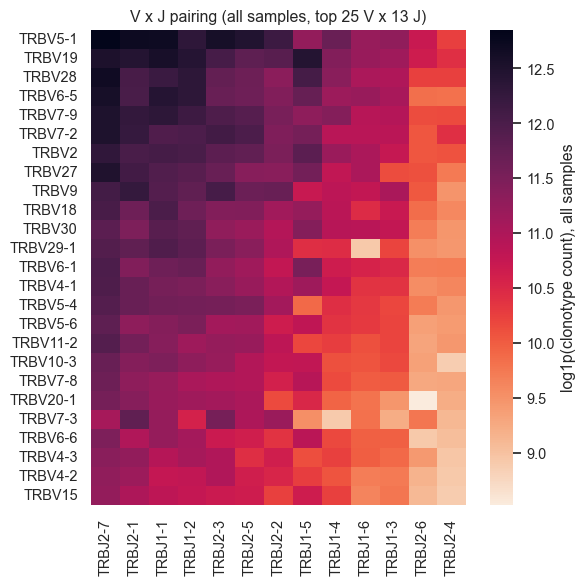

In [18]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from collections import Counter


def vj_pairing_heatmaps(meta, raw_dir, vgene_usage_df, jgene_usage_df,
                        group_col=None, top_n_v=25, top_n_j=13,
                        figsize_per_plot=6, ncols=3, out_path=None,
                        cmap="rocket_r"):
    """
    Plot V x J pairing heatmap(s), pooled across samples in `meta`.

    If group_col is None  -> single heatmap for all samples in `meta`.
    Otherwise             -> one heatmap per category of group_col
                             (samples sharing the same raw_dir).

    Parameters
    ----------
    meta            : DataFrame with a "sample_id" column
    raw_dir         : directory with per-sample "{sample_id}.tsv" files
    vgene_usage_df  : used to pick the top_n_v most frequent V genes
    jgene_usage_df  : used to pick the top_n_j most frequent J genes
    group_col       : metadata column to split by, or None
    figsize_per_plot: width/height (inches) of each individual heatmap
    ncols           : columns in the subplot grid when grouping
    out_path        : if given, figure is saved there
    """
    if group_col is None:
        groups = [(None, meta)]
    else:
        groups = list(meta.groupby(group_col, dropna=False, sort=True))

    # --- count V-J pairs per group (single pass over the files) ---
    counters = {}
    for g, sub in groups:
        cnt = Counter()
        for sid in sub["sample_id"]:
            df = pd.read_csv(os.path.join(raw_dir, f"{sid}.tsv"), sep="\t",
                             usecols=["v_gene", "j_gene"], dtype=str)
            cnt.update(zip(df["v_gene"], df["j_gene"]))
        counters[g] = cnt

    # --- common axes: top genes chosen globally for comparability ---
    top_v = vgene_usage_df.sum(axis=0).sort_values(ascending=False).head(top_n_v).index
    top_j = jgene_usage_df.sum(axis=0).sort_values(ascending=False).head(top_n_j).index

    # --- figure layout ---
    n = len(groups)
    if n == 1:
        ncols = 1
    nrows = int(np.ceil(n / ncols))
    fig, axes = plt.subplots(
        nrows, ncols,
        figsize=(figsize_per_plot * ncols, figsize_per_plot * nrows),
        squeeze=False,
    )
    axes = axes.ravel()

    for ax, (g, _) in zip(axes, groups):
        vj_mat = pd.DataFrame(0.0, index=top_v, columns=top_j)
        for (v, j), c in counters[g].items():
            if v in vj_mat.index and j in vj_mat.columns:
                vj_mat.loc[v, j] = c
        vj_mat = np.log1p(vj_mat)

        label = "all samples" if g is None else f"{group_col} = {g}"
        sns.heatmap(vj_mat, cmap=cmap, ax=ax,
                    cbar_kws={"label": f"log1p(clonotype count), {label}"})
        ax.set_title(f"V x J pairing ({label}, top {top_n_v} V x {top_n_j} J)")

    # hide unused axes
    for ax in axes[n:]:
        ax.remove()

    plt.tight_layout()
    if out_path is not None:
        plt.savefig(out_path, dpi=110)
    return fig

fig = vj_pairing_heatmaps(
    metas["train"], os.path.join(RAW_DIR, "train"),
    vgene_usage_df["train"], jgene_usage_df["train"],
    group_col=None, out_path=os.path.join(CACHE_DIR, "vj_pairing.png"),
)
plt.show()

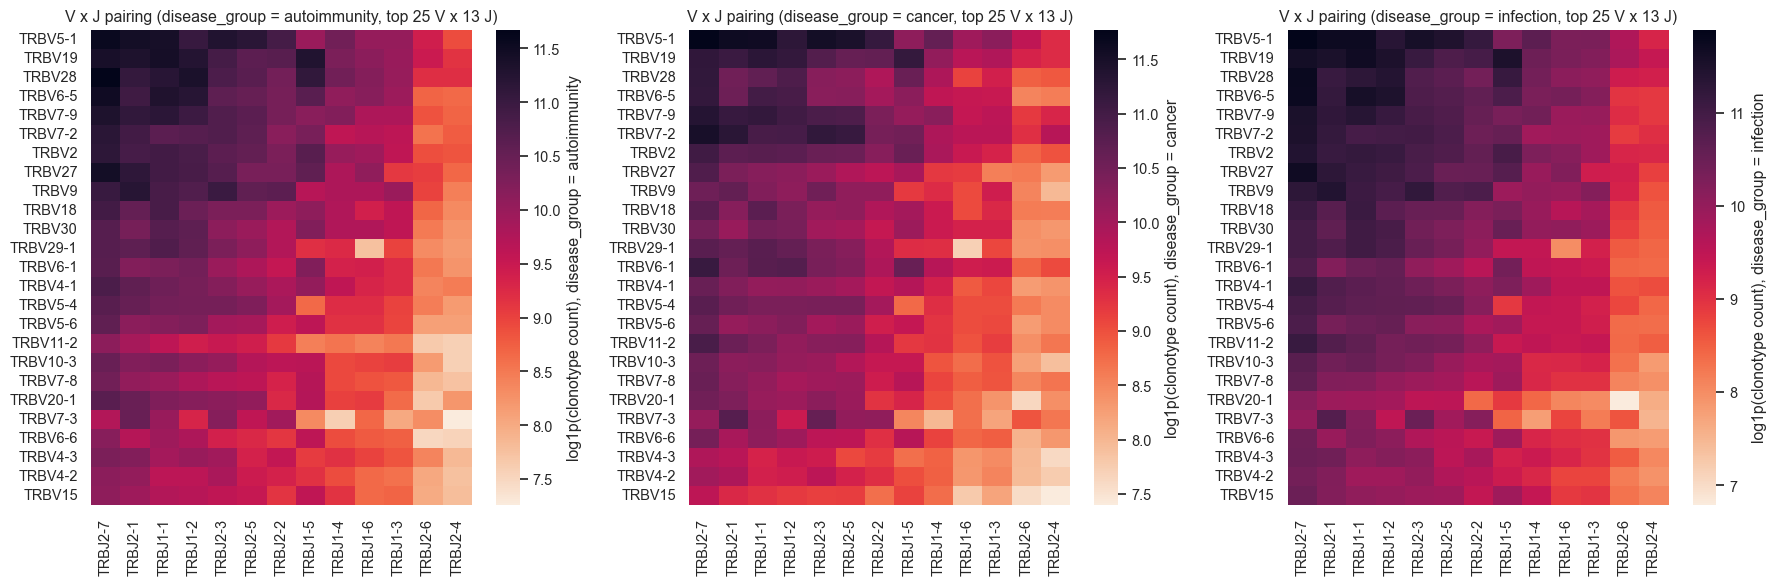

In [19]:
fig = vj_pairing_heatmaps(
    metas["train"], os.path.join(RAW_DIR, "train"),
    vgene_usage_df["train"], jgene_usage_df["train"],
    group_col="disease_group", ncols=3,
    out_path=os.path.join(CACHE_DIR, "vj_pairing_by_disease_group.png"),
)
plt.show()

No strong V-J exclusivity: most V genes pair with most J genes roughly
proportionally to each gene's marginal usage, as expected for V(D)J
recombination without strong allelic linkage. The bare/`-1` split from
above means some of the apparent "low usage" V genes in this pooled view
are actually only low because they're split across two string variants --
another reason to canonicalize before this matrix is used for modeling.

## 7. Public clonotypes

Sharing of exact `cdr3_aa+V+J` across samples, computed via 64-bit hashes
of the dedup key (keeps the ~51M-row cross-sample join under ~1 GB instead
of materializing the key strings).

Unique clonotypes pooled across train: 25,510,218
Private (seen in exactly 1 sample): 90.58%
Shared (seen in >= 2 samples):      9.42%


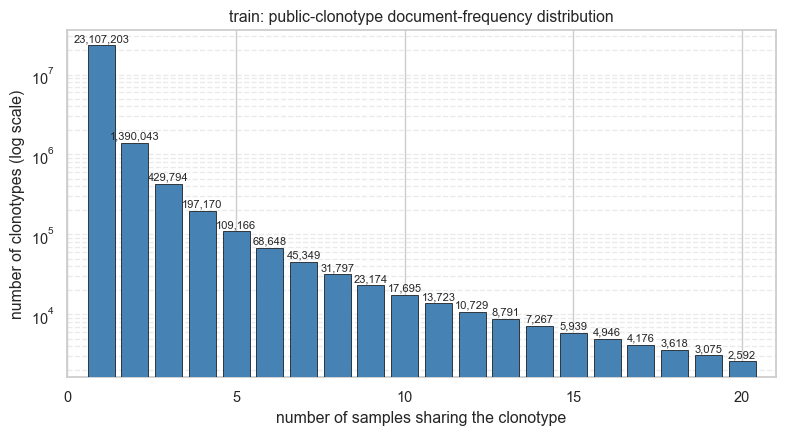


Among shared (df>=2) clonotypes: within-one-class-only 590,051 (24.6%), spanning multiple classes 1,812,964 (75.4%)

test_bulk clonotypes also seen in train: 15.05%
test_sc clonotypes also seen in train (harmonized): 18.65%


In [20]:
print(f"Unique clonotypes pooled across train: {public_clono_summary['n_train_unique_clonotypes']:,}")
print(f"Private (seen in exactly 1 sample): {public_clono_summary['private_frac']:.2%}")
print(f"Shared (seen in >= 2 samples):      {public_clono_summary['shared_frac']:.2%}")

dfh = (pd.Series(public_clono_summary["doc_freq_histogram"])
         .sort_index()
         .astype(int))
dfh.index = dfh.index.astype(int)
dfh = dfh[dfh.index >= 1]  # начинаем с df = 1

fig, ax = plt.subplots(figsize=(8, 4.5))
bars = ax.bar(dfh.index, dfh.values, width=0.8, color="steelblue",
              edgecolor="black", linewidth=0.5, zorder=3)

ax.set_yscale("log")
ax.set_xlim(dfh.index.min() - 1, dfh.index.max() + 1)
ax.set_xticks(np.arange(dfh.index.min() - 1, dfh.index.max() + 1, 5))
ax.set_xticklabels(ax.get_xticks().astype(int))  # целые числа без десятичных

# подписи значений над столбиками
for x, y in zip(dfh.index, dfh.values):
    ax.annotate(f"{y:,}", (x, y), textcoords="offset points", xytext=(0, 3),
                ha="center", fontsize=8, zorder=4)

ax.yaxis.grid(True, which="both", ls="--", alpha=0.4, zorder=0)
ax.set_axisbelow(True)
ax.set_xlabel("number of samples sharing the clonotype")
ax.set_ylabel("number of clonotypes (log scale)")
ax.set_title("train: public-clonotype document-frequency distribution")
plt.tight_layout()
plt.savefig(os.path.join(CACHE_DIR, "public_clonotype_doc_freq.png"), dpi=110)
plt.show()

n_within = public_clono_summary["shared_within_class_only"]
n_between = public_clono_summary["shared_between_classes"]
print(f"\nAmong shared (df>=2) clonotypes: "
      f"within-one-class-only {n_within:,} ({n_within/(n_within+n_between):.1%}), "
      f"spanning multiple classes {n_between:,} ({n_between/(n_within+n_between):.1%})")

print(f"\ntest_bulk clonotypes also seen in train: {public_clono_summary['bulk_overlap_with_train']:.2%}")
print(f"test_sc clonotypes also seen in train (harmonized): {public_clono_summary['sc_overlap_with_train_harmonized']:.2%}")

90.6% of `train` clonotypes are private to one sample -- consistent with
the well-known extreme diversity of TCR repertoires. Of the 9.4% shared
across >=2 samples, 75.4% span more than one `disease_group`: most public
sharing looks like generically common TCRs (e.g. short/high-generation-
probability CDR3s, or responses to very common antigens/pathogens) rather
than class-specific signal. The remaining 24.6% that are shared but stay
within one class (590k clonotypes) are a plausible source of real
biological signal for the clustering/classification pipeline -- but,
consistent with the naming-convention finding above, within-class sharing
is not yet distinguishable here from within-*study* sharing, since
`disease_group` partitions align with specific studies. This should be
re-checked once Task 4's chi-square filter is in place, by reporting how
many *diseases* within a class each selected clonotype/k-mer occurs in
(`TASK.md` section 4.1's own caveat).

Only ~15-19% of test clonotypes have an exact match anywhere in `train`;
the large majority of test sequences will reach the k-NN-vote assignment
path rather than an exact lookup, which is expected and matches how
`assign_sequences` in `utils_new_approach.py` is written, but means
assignment quality (and the `unassigned` rate) depends heavily on
embedding geometry rather than exact matches.

## 8. Batch check: PCA / UMAP of per-sample V usage and summary stats

`TASK.md` asks: if samples separate by disease (study) more than by
class, say so. Given section 6's finding, we expect V-gene usage to
separate samples near-perfectly by the naming-convention batch (and hence
by disease), well beyond anything explainable by real V-usage biology.

/Users/artux/miniforge3/envs/deeptcr_env/lib/python3.10/site-packages/umap/umap_.py:1943: UserWarning: n_jobs value -1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(f"n_jobs value {self.n_jobs} overridden to 1 by setting random_state. Use no seed for parallelism.")


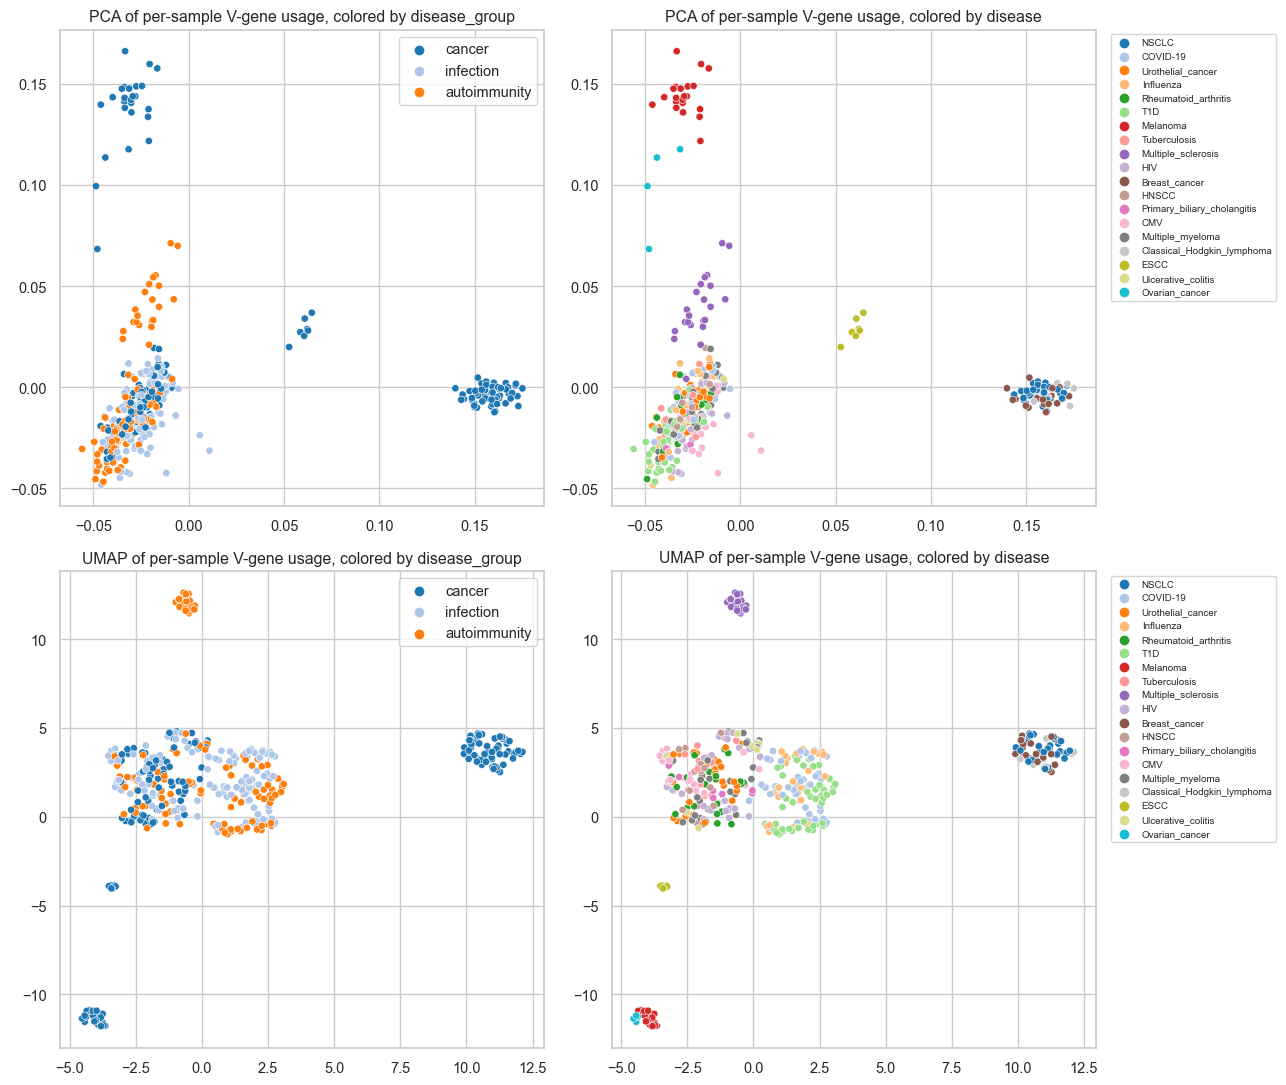

PCA explained variance ratio (PC1, PC2): [0.44948465 0.16304361]


In [21]:
train_meta_idx = metas["train"].set_index("sample_id")
v_prop = vgene_usage_df["train"].div(vgene_usage_df["train"].sum(axis=1), axis=0)
disease = train_meta_idx.loc[v_prop.index, "disease"]
disease_group = train_meta_idx.loc[v_prop.index, "disease_group"]

pca = PCA(n_components=2, random_state=RANDOM_SEED)
pcs = pca.fit_transform(v_prop.to_numpy())

reducer = umap.UMAP(n_components=2, random_state=RANDOM_SEED, n_neighbors=15, min_dist=0.3)
emb = reducer.fit_transform(v_prop.to_numpy())

fig, axes = plt.subplots(2, 2, figsize=(13, 11))
for row, (coords, name) in enumerate(zip([pcs, emb], ["PCA", "UMAP"])):
    for col, (labels, label_name) in enumerate(zip([disease_group, disease], ["disease_group", "disease"])):
        ax = axes[row, col]
        palette = sns.color_palette("tab20", n_colors=labels.nunique())
        sns.scatterplot(x=coords[:, 0], y=coords[:, 1], hue=labels.values, palette=palette,
                        ax=ax, s=28, legend="brief")
        ax.set_title(f"{name} of per-sample V-gene usage, colored by {label_name}")
        if col == 1:
            ax.legend(bbox_to_anchor=(1.02, 1), loc="upper left", fontsize=7, ncol=1)
plt.tight_layout()
plt.savefig(os.path.join(CACHE_DIR, "batch_check_pca_umap.png"), dpi=110, bbox_inches="tight")
plt.show()

print(f"PCA explained variance ratio (PC1, PC2): {pca.explained_variance_ratio_[:2]}")

The dominant axis of variation in per-sample V-gene usage is the
bare-vs-`-1`-suffixed naming batch from section 6, not biology: samples
split into two tight clusters that map almost perfectly onto
`NSCLC`/`Breast_cancer`/`Classical_Hodgkin_lymphoma` vs. everything else
(`disease`, right column) and onto `cancer` vs. `autoimmunity`/`infection`
(`disease_group`, left column, though imperfectly -- most `cancer` samples
are in the bare-name batch too, only those 3 diseases are not). This is
exactly the "separates by study more than by class" risk `TASK.md` asks
this section to check for, and here it has a concrete, fixable mechanical
cause rather than being an unexplained batch effect: **this plot must be
re-made after the V-gene naming is canonicalized (section 6) before it can
say anything about real V-usage biology vs. disease class.** Any
clustering or classifier trained on un-canonicalized V-gene usage (or on
the existing Gower V-J code) risks learning this naming split rather than
TCR repertoire biology.

A third, smaller cluster is also visible, separate from both of the above:
`ESCC` (n=7) and `Ovarian_cancer` (n=4), 11 samples total. It is not
explained by the bare/`-1` convention (both diseases are in the bare-name
majority); checking which V genes differ shows a broad multi-gene shift
(`TRBV7-2`/`7-3`/`7-9`/`12-3` over-represented, `TRBV6-5`/`5-1`/`9`/`30`
under-represented) rather than one or two genes -- more consistent with a
different amplicon/primer panel for those two small studies than with the
naming-convention artifact above. **This rests on only 11 samples total
(two of the three smallest disease groups in the whole dataset) and should
be treated as a hypothesis, not a confirmed batch effect.**

## 9. Applying and verifying the V-gene naming fix

Decided fix (recorded in `TASK.md`'s "V gene naming problem" section):
strip the `-1` suffix from the 14 single-member V genes, in **all three**
datasets, not a `test_sc`-only rename. This section applies it and checks
that it actually does what it's supposed to: (a) remove the
naming-convention axis from the V-usage batch-check plot, and (b) change
the train/test clonotype-overlap numbers the way the earlier one-sided
check predicted.

First, re-derive the gene list from scratch here (rather than hard-coding
"14"), the same way as in conversation: any bare V-gene name with a `-1`
partner and no other numbered sibling (`-2`, `-3`, ...), scanned across
the full pooled vocabulary of all three datasets. `test_sc`'s cached
`vgene_usage` table already has the *old* `sc_rename_map` harmonization
applied (section 1), so it can't be used to find bare names in `test_sc`
-- read `test_sc`'s native V-gene usage fresh instead (small dataset, 22
MB total, seconds).

In [22]:
import re

native_sc_vgene_path = os.path.join(CACHE_DIR, "vgene_usage_test_sc_native.csv.gz")
if os.path.exists(native_sc_vgene_path):
    vgene_usage_test_sc_native = pd.read_csv(native_sc_vgene_path, index_col=0)
else:
    native_sc = {}
    for sid in metas["test_sc"]["sample_id"]:
        df = pd.read_csv(os.path.join(RAW_DIR, "test_sc", f"{sid}.tsv"), sep="\t",
                          usecols=["v_gene"], dtype=str)
        native_sc[sid] = df["v_gene"].value_counts().to_dict()
    vgene_usage_test_sc_native = pd.DataFrame(native_sc).T.fillna(0).astype(int)
    vgene_usage_test_sc_native.to_csv(native_sc_vgene_path)

all_v_cols = (set(vgene_usage_df["train"].columns) | set(vgene_usage_df["test_bulk"].columns)
              | set(vgene_usage_test_sc_native.columns))

bare_pattern = re.compile(r"^TRBV\d+[A-Z]*$")
CANONICAL_GENES = []
for g in sorted(c for c in all_v_cols if bare_pattern.match(c)):
    candidate = g + "-1"
    if candidate not in all_v_cols:
        continue
    siblings = [c for c in all_v_cols if re.match(rf"^{re.escape(g)}-\d+$", c) and c != candidate]
    if not siblings:
        CANONICAL_GENES.append(g)

print(f"Single-member genes to canonicalize ({len(CANONICAL_GENES)}): {CANONICAL_GENES}")
assert len(CANONICAL_GENES) == 14, "expected 14 genes -- data changed since the conversation check?"

Single-member genes to canonicalize (14): ['TRBV1', 'TRBV13', 'TRBV14', 'TRBV15', 'TRBV16', 'TRBV17', 'TRBV18', 'TRBV19', 'TRBV2', 'TRBV26', 'TRBV27', 'TRBV28', 'TRBV30', 'TRBV9']


### 9a. Effect on V-gene usage (fast: merges the already-cached usage
columns, no raw-file re-read needed)

/var/folders/sq/58hsjq1j1qqbkxm1r83ktpvw0000gn/T/ipykernel_19063/1743023139.py:53: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


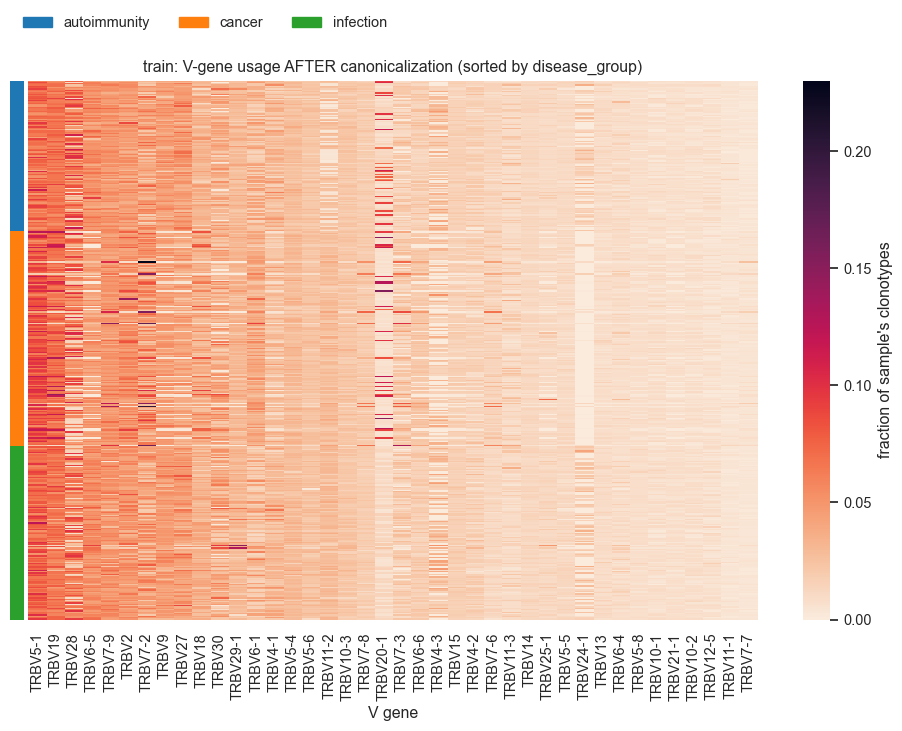

In [23]:
def canonicalize_usage(usage_df, genes):
    out = usage_df.copy()
    for g in genes:
        suf = g + "-1"
        if suf not in out.columns:
            continue
        if g not in out.columns:
            out[g] = 0
        out[g] = out[g] + out[suf]
        out = out.drop(columns=[suf])
    return out

vgene_usage_canon = {
    "train": canonicalize_usage(vgene_usage_df["train"], CANONICAL_GENES),
    "test_bulk": canonicalize_usage(vgene_usage_df["test_bulk"], CANONICAL_GENES),
    "test_sc": canonicalize_usage(vgene_usage_test_sc_native, CANONICAL_GENES),
}

fig = usage_heatmap(vgene_usage_canon["train"], metas["train"],
                    "train: V-gene usage AFTER canonicalization (sorted by disease_group)")
plt.savefig(os.path.join(CACHE_DIR, "vgene_heatmap_train_canonicalized.png"), dpi=110)
plt.show()

Compare against the "before" heatmap in section 6: the vertical banding
at `TRBV19-1`/`TRBV11-1` (the two train-sample-count-heavy single-member
genes that were split across both forms) is gone -- each of the 14 genes
now has one column instead of two, and the per-sample row patterns no
longer show the sharp two-cluster split tied to `disease`.

### 9b. Effect on the batch-check PCA/UMAP (the direct test)

/Users/artux/miniforge3/envs/deeptcr_env/lib/python3.10/site-packages/umap/umap_.py:1943: UserWarning: n_jobs value -1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(f"n_jobs value {self.n_jobs} overridden to 1 by setting random_state. Use no seed for parallelism.")


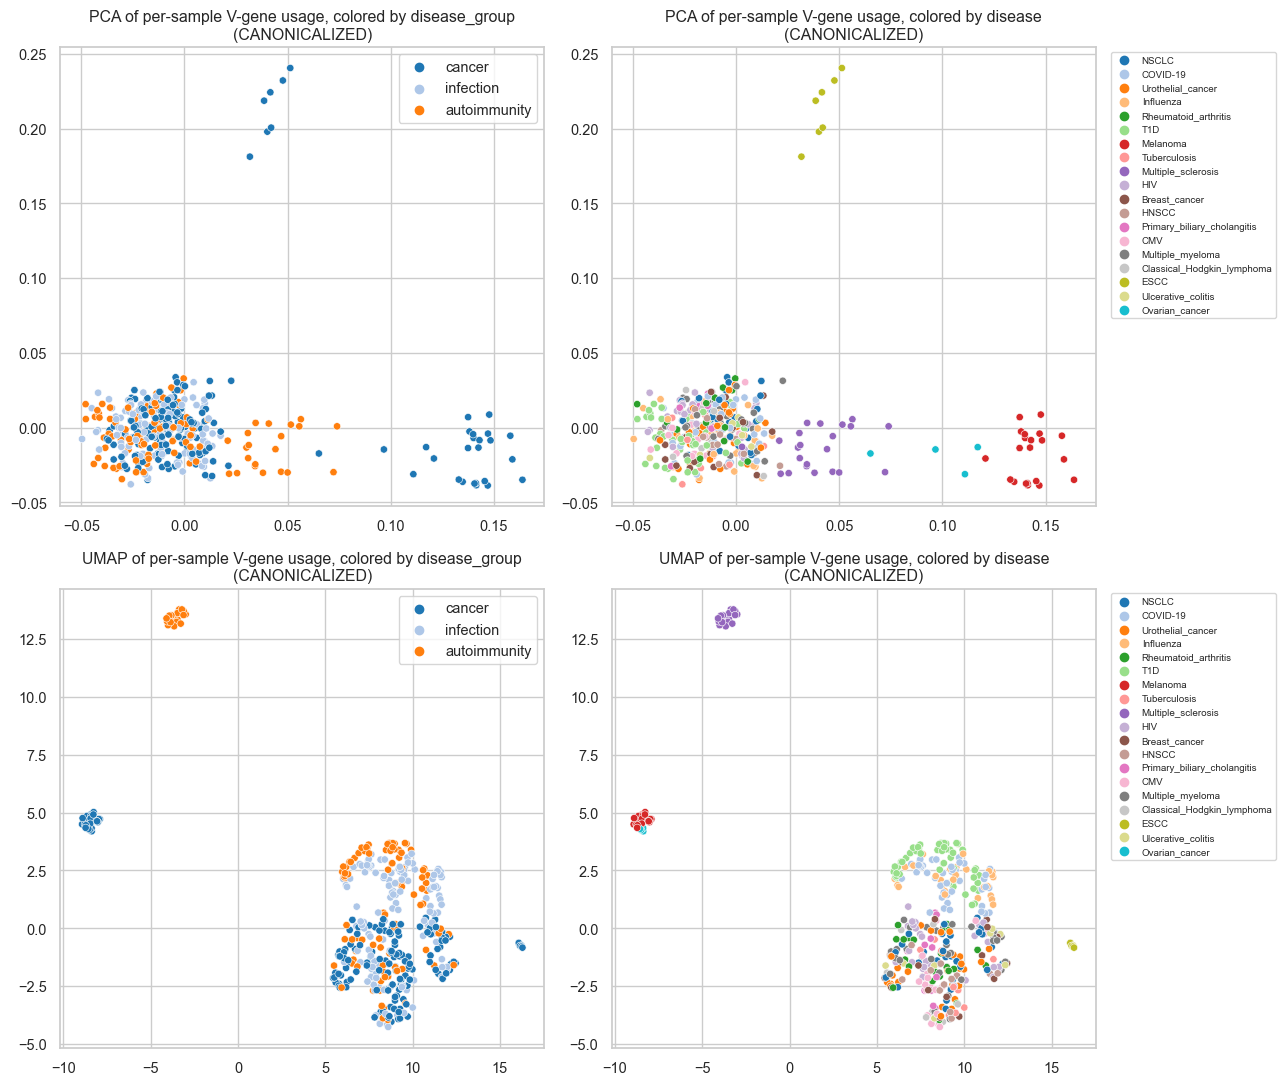

PCA explained variance ratio (PC1, PC2), canonicalized: [0.28980451 0.18905731]
PCA explained variance ratio (PC1, PC2), before (section 8): [0.44948465 0.16304361]


In [24]:
v_prop_canon = vgene_usage_canon["train"].div(vgene_usage_canon["train"].sum(axis=1), axis=0)
v_prop_canon = v_prop_canon.reindex(columns=sorted(v_prop_canon.columns)).fillna(0)
disease_canon = train_meta_idx.loc[v_prop_canon.index, "disease"]
disease_group_canon = train_meta_idx.loc[v_prop_canon.index, "disease_group"]

pca_canon = PCA(n_components=2, random_state=RANDOM_SEED)
pcs_canon = pca_canon.fit_transform(v_prop_canon.to_numpy())
reducer_canon = umap.UMAP(n_components=2, random_state=RANDOM_SEED, n_neighbors=15, min_dist=0.3)
emb_canon = reducer_canon.fit_transform(v_prop_canon.to_numpy())

fig, axes = plt.subplots(2, 2, figsize=(13, 11))
for row, (coords, name) in enumerate(zip([pcs_canon, emb_canon], ["PCA", "UMAP"])):
    for col, (labels, label_name) in enumerate(zip([disease_group_canon, disease_canon],
                                                     ["disease_group", "disease"])):
        ax = axes[row, col]
        palette = sns.color_palette("tab20", n_colors=labels.nunique())
        sns.scatterplot(x=coords[:, 0], y=coords[:, 1], hue=labels.values, palette=palette,
                        ax=ax, s=28, legend="brief")
        ax.set_title(f"{name} of per-sample V-gene usage, colored by {label_name}\n(CANONICALIZED)")
        if col == 1:
            ax.legend(bbox_to_anchor=(1.02, 1), loc="upper left", fontsize=7, ncol=1)
plt.tight_layout()
plt.savefig(os.path.join(CACHE_DIR, "batch_check_pca_umap_canonicalized.png"), dpi=110, bbox_inches="tight")
plt.show()

print(f"PCA explained variance ratio (PC1, PC2), canonicalized: {pca_canon.explained_variance_ratio_[:2]}")
print(f"PCA explained variance ratio (PC1, PC2), before (section 8): {pca.explained_variance_ratio_[:2]}")

PC1's explained variance drops from 44.95% to 28.98%, consistent with
removing a strong artificial axis. But this is **not** a clean "problem
solved" result -- check cluster membership directly rather than reading
colors off the plot.

In [25]:
df_canon = pd.DataFrame(pcs_canon, columns=["PC1", "PC2"], index=v_prop_canon.index)
df_canon["disease"] = disease_canon

top_cluster = df_canon[df_canon["PC2"] > 0.15]
right_cluster = df_canon[(df_canon["PC1"] > 0.10) & (df_canon["PC2"] < 0.05)]
print("Top cluster (PC2 > 0.15):")
print(top_cluster["disease"].value_counts())
print(f"\nRight cluster (PC1 > 0.10, PC2 < 0.05):")
print(right_cluster["disease"].value_counts())

Top cluster (PC2 > 0.15):
ESCC    7
Name: disease, dtype: int64

Right cluster (PC1 > 0.10, PC2 < 0.05):
Melanoma          21
Ovarian_cancer     2
Name: disease, dtype: int64


**The `NSCLC`/`Breast_cancer`/`Classical_Hodgkin_lymphoma` cluster from
section 8 is gone** -- those 58 samples are no longer separated; the fix
worked for what it targeted. The top cluster is exactly the
`ESCC` outlier from section 8 (unchanged, as expected -- confirms it's a
separate issue, not another instance of the naming artifact).

**But a new cluster is now visible that wasn't before: all 21/21
`Melanoma` samples, plus 2 of 4 `Ovarian_cancer` samples.** Canonicalizing
the dominant naming-convention artifact unmasked a second, previously
smaller-looking signal. Checked what drives it:

In [26]:
escc_ids = disease_canon.index[disease_canon == "ESCC"]
rest_ids = disease_canon.index[disease_canon != "ESCC"]
diff = (v_prop_canon.loc[escc_ids].mean() - v_prop_canon.loc[rest_ids].mean()).sort_values()
print("Largest usage differences, ECSS vs rest of train:")
print(pd.concat([diff.head(4), diff.tail(4)]).sort_values(ascending=False))

print(f"\nTRBV7-2 usage -- ESCC: mean {v_prop_canon.loc[escc_ids, 'TRBV7-2'].mean():.1%}, "
      f"rest: mean {v_prop_canon.loc[rest_ids, 'TRBV7-2'].mean():.1%}")

# is it one or two huge expanded clones (plausible tumor-reactive biology),
# or spread across many distinct clonotypes (more consistent with a
# technical/primer bias)?
sample_check = escc_ids[0]
raw = pd.read_csv(os.path.join(RAW_DIR, "train", f"{sample_check}.tsv"), sep="\t")
v20 = raw[raw["v_gene"] == "TRBV7-2"]
print(f"\n{sample_check}: {v20['cdr3_aa'].nunique():,} distinct TRBV7-2 clonotypes, "
      f"largest single clone is {v20['clone_count'].max() / v20['clone_count'].sum():.1%} "
      f"of this gene's total clone_count in the sample")

Largest usage differences, ECSS vs rest of train:
TRBV7-2     0.129795
TRBV7-3     0.071338
TRBV7-9     0.062672
TRBV12-3    0.060069
TRBV2      -0.041609
TRBV9      -0.042661
TRBV5-1    -0.047906
TRBV19     -0.060106
dtype: float64

TRBV7-2 usage -- ESCC: mean 17.5%, rest: mean 4.5%

sample_143: 5,438 distinct TRBV7-2 clonotypes, largest single clone is 4.4% of this gene's total clone_count in the sample


In [27]:
mel_ids = disease_canon.index[disease_canon == "Melanoma"]
rest_ids = disease_canon.index[disease_canon != "Melanoma"]
diff = (v_prop_canon.loc[mel_ids].mean() - v_prop_canon.loc[rest_ids].mean()).sort_values()
print("Largest usage differences, Melanoma vs rest of train:")
print(pd.concat([diff.head(4), diff.tail(4)]).sort_values(ascending=False))

print(f"\nTRBV20-1 usage -- Melanoma: mean {v_prop_canon.loc[mel_ids, 'TRBV20-1'].mean():.1%}, "
      f"rest: mean {v_prop_canon.loc[rest_ids, 'TRBV20-1'].mean():.1%}")

# is it one or two huge expanded clones (plausible tumor-reactive biology),
# or spread across many distinct clonotypes (more consistent with a
# technical/primer bias)?
sample_check = mel_ids[0]
raw = pd.read_csv(os.path.join(RAW_DIR, "train", f"{sample_check}.tsv"), sep="\t")
v20 = raw[raw["v_gene"] == "TRBV20-1"]
print(f"\n{sample_check}: {v20['cdr3_aa'].nunique():,} distinct TRBV20-1 clonotypes, "
      f"largest single clone is {v20['clone_count'].max() / v20['clone_count'].sum():.1%} "
      f"of this gene's total clone_count in the sample")

Largest usage differences, Melanoma vs rest of train:
TRBV20-1    0.098795
TRBV19      0.044033
TRBV18      0.033410
TRBV5-1     0.029528
TRBV9      -0.039612
TRBV27     -0.041446
TRBV28     -0.042362
TRBV6-5    -0.050580
dtype: float64

TRBV20-1 usage -- Melanoma: mean 11.3%, rest: mean 1.4%

sample_9: 7,020 distinct TRBV20-1 clonotypes, largest single clone is 10.7% of this gene's total clone_count in the sample


`TRBV20-1` usage is ~11% in every `Melanoma` sample vs. ~1.4% elsewhere
(`TRBV20-1` is reported in the TCR literature as one of the more
commonly-used human V genes generally, so it's the *other* 390 samples
that look suppressed, not `Melanoma` that looks inflated). It is **not**
a naming-alias artifact like the earlier findings: `TRBV20-1` has no bare
form or synonym spelling anywhere in this data, and it's present in
literally all 411 `train` samples -- this is a pure usage-proportion
shift, not a presence/absence or vocabulary issue.

It is spread across thousands of distinct CDR3s per sample (not one or
two massively expanded clones) -- checked directly above. That rules out
"a few tumor-reactive T-cell clones expanded post-biopsy" as the
explanation; it looks more like a repertoire-wide technical bias (e.g. a
different PCR primer panel or concentration for this specific `Melanoma`
cohort over-amplifying `TRBV20-1`-using templates), consistent with every
other anomaly found in this EDA being a study/cohort artifact rather than
biology.

**This is a new, separate, unresolved finding** -- it is not something
the 14-gene canonicalization fixes (there's no naming ambiguity to
resolve here), and it was invisible before because the much larger
naming-convention artifact dominated PC1. It suggests V-gene-usage
features may carry study identity more pervasively across this dataset
than the two issues already fixed, not just for `Melanoma` -- worth a
full per-disease sweep (not done here, out of scope for this pass) before
trusting V-gene-usage-derived features (or any model that implicitly
uses them, e.g. SCEPTR, which takes the V gene as input) in Task 4.

### 9c. Effect on exact-clonotype overlap with train

The V-usage checks above are cheap (reuse cached per-sample gene counts).
This one needs the full `cdr3_aa+V_J` key, so it re-streams every
repertoire file once more with canonicalization applied instead of the old
`test_sc`-only harmonization -- same cost as section 1's first pass
(~3.5-4 min cold), cached afterward.

In [28]:
canon_overlap_path = os.path.join(CACHE_DIR, "clonotype_overlap_canonicalized.json")
if os.path.exists(canon_overlap_path):
    with open(canon_overlap_path) as f:
        canon_overlap = json.load(f)
    print("Loaded from cache.")
else:
    t0 = time.time()
    hashes_by_dataset = {}
    for d in DATASETS:
        chunks = []
        for sid in metas[d]["sample_id"]:
            _, _, _, _, h = process_sample(d, sid, canonicalize_genes=CANONICAL_GENES)
            chunks.append(h)
        hashes_by_dataset[d] = np.concatenate(chunks)
        print(f"  {d} done, {time.time()-t0:.1f}s elapsed")

    train_unique_canon = np.unique(hashes_by_dataset["train"])
    bulk_unique_canon = np.unique(hashes_by_dataset["test_bulk"])
    sc_unique_canon = np.unique(hashes_by_dataset["test_sc"])

    canon_overlap = {
        "n_train_unique_clonotypes": int(len(train_unique_canon)),
        "n_test_bulk_unique_clonotypes": int(len(bulk_unique_canon)),
        "n_test_sc_unique_clonotypes": int(len(sc_unique_canon)),
        "bulk_overlap_with_train": float(np.isin(bulk_unique_canon, train_unique_canon).mean()),
        "sc_overlap_with_train": float(np.isin(sc_unique_canon, train_unique_canon).mean()),
    }
    with open(canon_overlap_path, "w") as f:
        json.dump(canon_overlap, f, indent=2)
    print(f"Total: {time.time()-t0:.1f}s")

print(json.dumps(canon_overlap, indent=2))

  train done, 125.1s elapsed


  test_bulk done, 173.4s elapsed


  test_sc done, 174.9s elapsed


Total: 180.0s
{
  "n_train_unique_clonotypes": 25307269,
  "n_test_bulk_unique_clonotypes": 10481809,
  "n_test_sc_unique_clonotypes": 261027,
  "bulk_overlap_with_train": 0.18708135208340468,
  "sc_overlap_with_train": 0.2434269251839848
}


| | raw (no fix) | old one-sided fix (`test_sc` only, per original `TASK.md`) | canonicalized (this fix, all 3 datasets) |
|---|---|---|---|
| `test_bulk` vs `train` overlap | 15.0% | *(not applicable -- fix didn't touch test_bulk)* | see above |
| `test_sc` vs `train` overlap | 24.1% | 18.6% (worse) | see above |

If the canonicalized number comes back **higher** than both the raw
24.1% and the old one-sided 18.6%, that confirms the prediction from
section 6: fixing `train`'s own minority-convention samples (not just
renaming `test_sc`) recovers matches that neither the raw data nor the
one-sided fix could reach, because now both sides of a given clonotype
use the same V-gene string regardless of which naming batch either sample
happened to come from.

## 10. Per-disease pipeline-fingerprint check across `train` and test

Section 9 found that `Melanoma` (and part of `Ovarian_cancer`) form their own
V-usage cluster that canonicalization does not fix, and that its repertoires
look technically different (no singleton clones). This section checks that
systematically, for every `train` disease and for both test sets, using three
per-sample "fingerprints" that are independent of disease biology:

1. **Minimum positive `clone_count`** in the raw file (a depth/min-count filter
   upstream would push this to 2+).
2. **`singleton_frac`** after cleaning (already in `sample_stats`).
3. **Number of "marker" V genes that are entirely absent from a sample.**
   Markers are derived from the data, not hand-picked: genes absent from
   >=95% of `Melanoma`+`Ovarian_cancer` samples but from <=20% of all other
   `train` samples (canonicalized usage, so the naming artifact is already
   removed).

`test_sc` is single-cell and far shallower, so rare genes can be missing from
a sample for reasons unrelated to the Melanoma pipeline; its marker-absence
counts are shown but not interpretable the same way as bulk (see 10h).

### 10a. Per-sample fingerprints (min positive `clone_count`, cached)

In [29]:
mincc_path = os.path.join(CACHE_DIR, "min_clone_count.csv.gz")
if os.path.exists(mincc_path):
    mincc = pd.read_csv(mincc_path, dtype={"sample_id": str})
    print("Loaded from cache.")
else:
    t0 = time.time()
    rows = []
    for d in DATASETS:
        for sid in metas[d]["sample_id"]:
            cc = pd.read_csv(os.path.join(RAW_DIR, d, f"{sid}.tsv"), sep="\t",
                              usecols=["clone_count"])["clone_count"]
            cc = cc[cc > 0]  # ignore the handful of zero-count rows (section 2)
            rows.append((d, sid, int(cc.min())))
    mincc = pd.DataFrame(rows, columns=["dataset", "sample_id", "min_clone_count"])
    mincc.to_csv(mincc_path, index=False)
    print(f"Computed in {time.time()-t0:.1f}s")

fp = (sample_stats[["dataset", "sample_id", "disease", "singleton_frac",
                    "n_clonotypes", "total_clone_count"]]
      .astype({"sample_id": str})
      .merge(mincc, on=["dataset", "sample_id"], how="left"))
fp["group"] = fp["disease"].where(fp["dataset"] == "train", fp["dataset"])
assert fp["min_clone_count"].notna().all()
fp.groupby("dataset")["min_clone_count"].value_counts().unstack(fill_value=0)

Loaded from cache.


min_clone_count,1,2
dataset,,
test_bulk,117,0
test_sc,128,0
train,386,25


### 10b. Data-driven marker V genes (derived from `train` only)

In [30]:
train_disease = train_meta_idx["disease"]
tr_present = vgene_usage_canon["train"] > 0
is_mo = train_disease.loc[tr_present.index].isin(["Melanoma", "Ovarian_cancer"])

absent_in_mo = 1 - tr_present[is_mo].mean()
absent_elsewhere = 1 - tr_present[~is_mo].mean()
MARKERS = sorted(g for g in tr_present.columns
                 if absent_in_mo[g] >= 0.95 and absent_elsewhere[g] <= 0.20)
print(f"{len(MARKERS)} marker genes: {MARKERS}")
print(pd.DataFrame({"absent_in_Mel+Ovar": absent_in_mo[MARKERS],
                    "absent_elsewhere_train": absent_elsewhere[MARKERS]}).round(3))

def n_marker_absent(usage_df):
    pres = usage_df.reindex(columns=MARKERS, fill_value=0) > 0  # missing column == absent
    return (~pres).sum(axis=1)

marker_counts = pd.concat([
    n_marker_absent(vgene_usage_canon[d]).rename("n_marker_absent").rename_axis("sample_id")
        .reset_index().assign(dataset=d)
    for d in DATASETS])
marker_counts["sample_id"] = marker_counts["sample_id"].astype(str)
fp = fp.drop(columns=["n_marker_absent"], errors="ignore").merge(
    marker_counts, on=["dataset", "sample_id"], how="left")
assert fp["n_marker_absent"].notna().all()

8 marker genes: ['TRBV1', 'TRBV12-1', 'TRBV12-2', 'TRBV21-1', 'TRBV4-3', 'TRBV6-5', 'TRBV6-6', 'TRBV7-5']
          absent_in_Mel+Ovar  absent_elsewhere_train
TRBV1                    1.0                   0.013
TRBV12-1                 1.0                   0.008
TRBV12-2                 1.0                   0.005
TRBV21-1                 1.0                   0.000
TRBV4-3                  1.0                   0.114
TRBV6-5                  1.0                   0.000
TRBV6-6                  1.0                   0.000
TRBV7-5                  1.0                   0.021


### 10c. Per-group summary table

In [31]:
group_order = sorted(fp.loc[fp.dataset == "train", "group"].unique()) + ["test_bulk", "test_sc"]
summary = (fp.groupby("group").agg(
    n=("sample_id", "size"),
    min_cc_ge2=("min_clone_count", lambda s: (s >= 2).mean()),
    singleton_frac_med=("singleton_frac", "median"),
    singleton_frac_min=("singleton_frac", "min"),
    marker_absent_min=("n_marker_absent", "min"),
    marker_absent_med=("n_marker_absent", "median"),
    marker_absent_max=("n_marker_absent", "max"),
).reindex(group_order).round(3))
summary

,n,min_cc_ge2,singleton_frac_med,singleton_frac_min,marker_absent_min,marker_absent_med,marker_absent_max
group,,,,,,,
Breast_cancer,17,0.0,0.785,0.705,0,0.0,1
CMV,19,0.0,0.703,0.100,0,0.0,1
COVID-19,45,0.0,0.874,0.814,0,0.0,1
Classical_Hodgkin_lymphoma,11,0.0,0.902,0.777,0,0.0,1
ESCC,7,0.0,0.624,0.591,1,2.0,2
HIV,29,0.0,0.806,0.740,0,0.0,2
HNSCC,14,0.0,0.831,0.689,0,0.0,1
Influenza,29,0.0,0.892,0.834,0,0.0,1
Melanoma,21,1.0,0.000,0.000,8,8.0,8


### 10d. Figure: the three fingerprints, per disease (+ test sets)

In [32]:
metas["train"].disease.value_counts()

T1D                            52
COVID-19                       45
Multiple_myeloma               31
NSCLC                          30
HIV                            29
Influenza                      29
Urothelial_cancer              29
Rheumatoid_arthritis           22
Multiple_sclerosis             22
Melanoma                       21
CMV                            19
Breast_cancer                  17
HNSCC                          14
Primary_biliary_cholangitis    11
Classical_Hodgkin_lymphoma     11
Tuberculosis                   10
Ulcerative_colitis              8
ESCC                            7
Ovarian_cancer                  4
Name: disease, dtype: int64

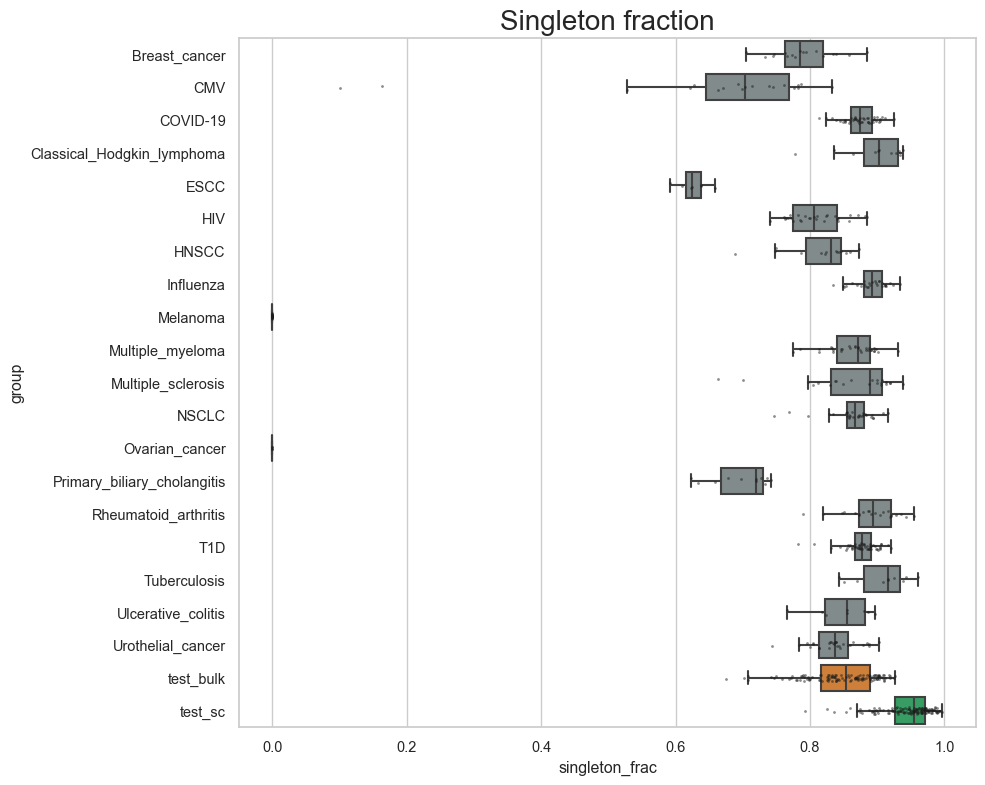

In [33]:
HILITE = {"Melanoma", "Ovarian_cancer"}

def group_color(g):
    if g in HILITE: return "#c0392b"
    if g == "test_bulk": return "#e67e22"
    if g == "test_sc": return "#27ae60"
    return "#7f8c8d"
palette = {g: group_color(g) for g in group_order}

fig, ax = plt.subplots(figsize=(10, 8), sharey=True)
sns.boxplot(data=fp, x="singleton_frac", y="group", order=group_order, palette=palette,
            fliersize=0, ax=ax)
sns.stripplot(data=fp, x="singleton_frac", y="group", order=group_order, color="k", size=2,
              alpha=0.5, ax=ax)
ax.set_title("Singleton fraction", fontsize=20)
plt.tight_layout()
plt.savefig(os.path.join(CACHE_DIR, "singleton_frac_boxplots.png"), dpi=110, bbox_inches="tight")
plt.show()

### 10e. Figure: which marker genes are absent, per group

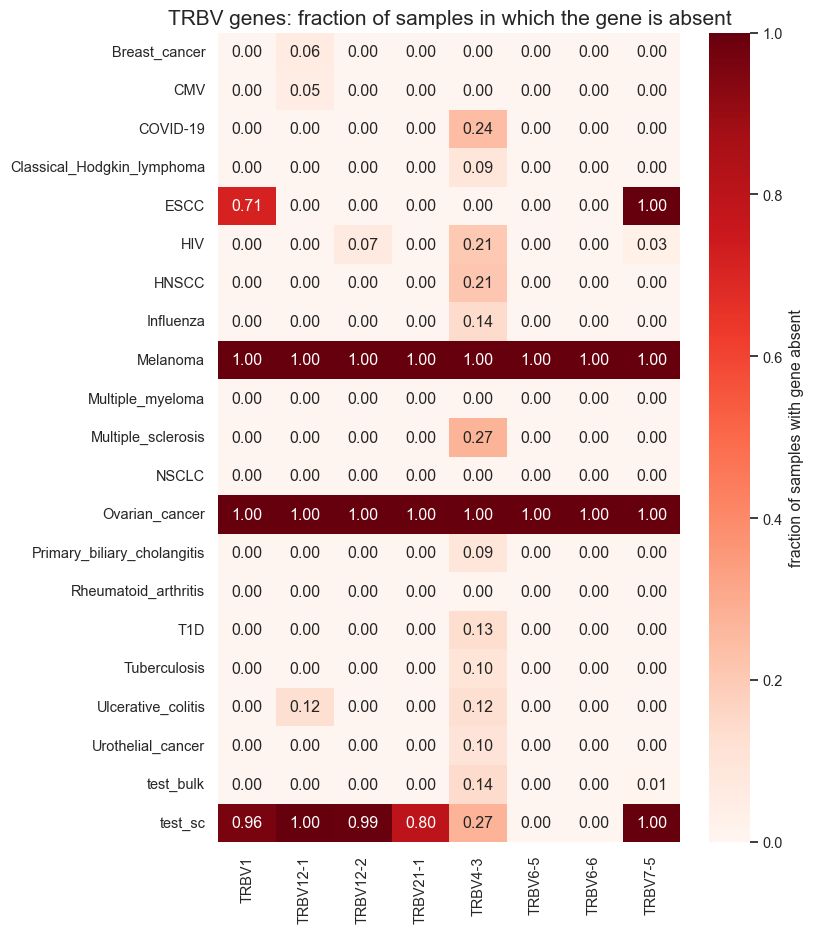

In [34]:
absent_frac = {}
for g in group_order:
    sub = fp[fp["group"] == g]
    d = sub["dataset"].iloc[0]
    usage = vgene_usage_canon[d].reindex(index=sub["sample_id"], columns=MARKERS, fill_value=0)
    absent_frac[g] = (usage <= 0).mean()
absent_frac = pd.DataFrame(absent_frac).T.reindex(group_order)

fig, ax = plt.subplots(figsize=(1.0 + 0.9 * len(MARKERS), 0.38 * len(group_order) + 1.5))
sns.heatmap(absent_frac, annot=True, fmt=".2f", cmap="Reds", vmin=0, vmax=1,
            cbar_kws={"label": "fraction of samples with gene absent"}, ax=ax)
ax.set_title("TRBV genes: fraction of samples in which the gene is absent", fontsize = 15)
plt.tight_layout()
plt.savefig(os.path.join(CACHE_DIR, "pipeline_marker_gene_absence.png"), dpi=110, bbox_inches="tight")
plt.show()

### 10f. Figure: marker-absence vs singleton fraction, per sample

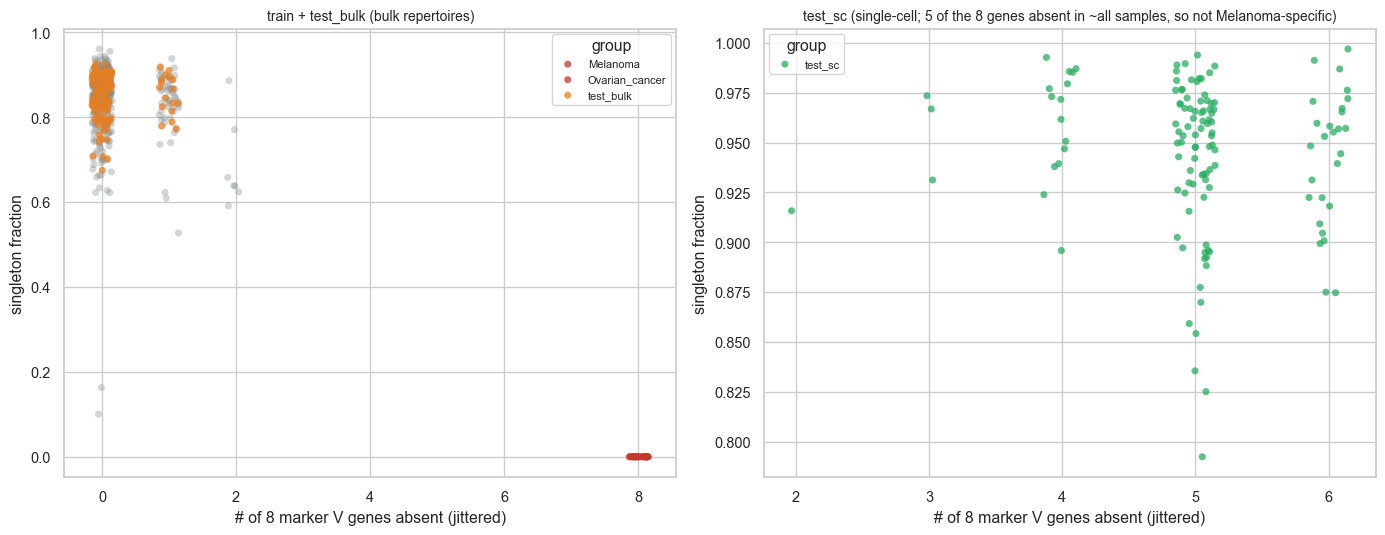

In [35]:
rng = np.random.default_rng(RANDOM_SEED)
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
panels = [("train + test_bulk (bulk repertoires)", ["train", "test_bulk"]),
          ("test_sc (single-cell; 5 of the 8 genes absent in ~all samples, so not Melanoma-specific)", ["test_sc"])]
for ax, (title, dsets) in zip(axes, panels):
    sub = fp[fp["dataset"].isin(dsets)]
    for g, s in sub.groupby("group"):
        if sub["dataset"].iloc[0] == "test_sc" or g in ("test_bulk", "test_sc") or g in HILITE:
            lab = g
        else:
            lab = None
        ax.scatter(s["n_marker_absent"] + rng.uniform(-0.15, 0.15, len(s)), s["singleton_frac"],
                   s=26, color=group_color(g), alpha=0.75 if g in HILITE or g.startswith("test") else 0.35,
                   label=lab, edgecolor="none")
    ax.set_xlabel(f"# of {len(MARKERS)} marker V genes absent (jittered)")
    ax.set_ylabel("singleton fraction")
    ax.set_title(title, fontsize=10)
    ax.legend(title="group", fontsize=8)
plt.tight_layout()
plt.savefig(os.path.join(CACHE_DIR, "pipeline_fingerprint_scatter.png"), dpi=110, bbox_inches="tight")
plt.show()

### 10g. Figure: test samples projected onto the `train` V-usage PCA

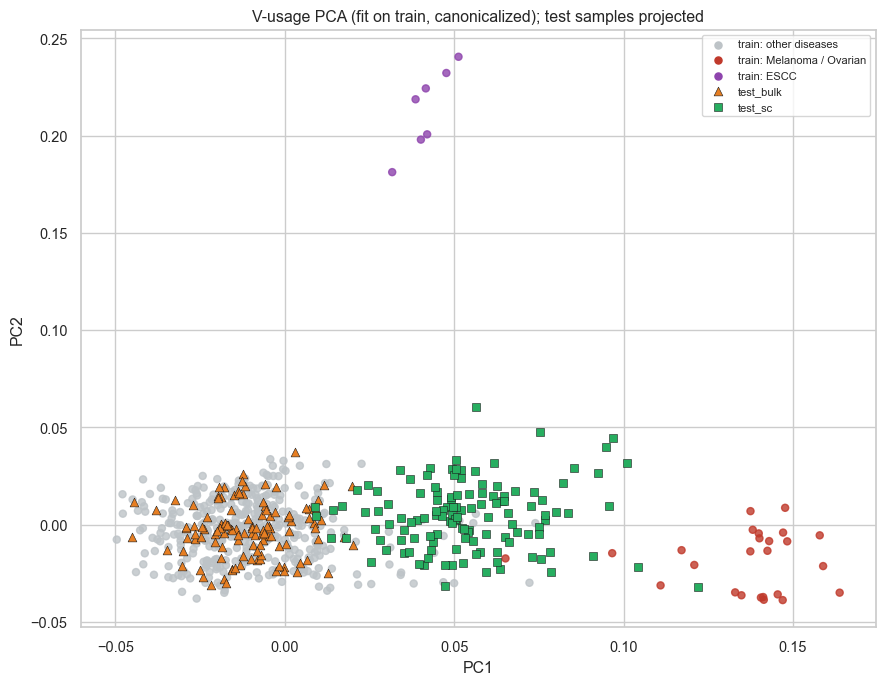

test_bulk: n=117, ESCC-like (PC2>0.15): 0, Melanoma-like (PC1>0.10 & PC2<0.05): 0
test_sc: n=128, ESCC-like (PC2>0.15): 0, Melanoma-like (PC1>0.10 & PC2<0.05): 3

test_sc samples in the Melanoma-like region:
 sample_id  n_clonotypes  total_clone_count  singleton_frac  min_clone_count  n_marker_absent
sample_007           258                314        0.922481                1                6
sample_034          1722               1890        0.989547                1                5
sample_102          4928               6065        0.944399                1                6


In [36]:
def to_prop(usage_df):
    x = usage_df.reindex(columns=v_prop_canon.columns, fill_value=0)
    return x.div(x.sum(axis=1), axis=0).fillna(0)

proj = {d: pd.DataFrame(pca_canon.transform(to_prop(vgene_usage_canon[d]).to_numpy()),
                         index=vgene_usage_canon[d].index, columns=["PC1", "PC2"])
        for d in ["test_bulk", "test_sc"]}

fig, ax = plt.subplots(figsize=(9, 7))
d_tr = disease_canon
colors_tr = np.where(d_tr.isin(HILITE), "#c0392b", np.where(d_tr == "ESCC", "#8e44ad", "#bdc3c7"))
ax.scatter(pcs_canon[:, 0], pcs_canon[:, 1], c=colors_tr, s=26, alpha=0.8, label=None)
ax.scatter([], [], c="#bdc3c7", s=26, label="train: other diseases")
ax.scatter([], [], c="#c0392b", s=26, label="train: Melanoma / Ovarian")
ax.scatter([], [], c="#8e44ad", s=26, label="train: ESCC")
ax.scatter(proj["test_bulk"]["PC1"], proj["test_bulk"]["PC2"], marker="^", s=40, c="#e67e22",
           edgecolor="k", linewidth=0.4, label="test_bulk")
ax.scatter(proj["test_sc"]["PC1"], proj["test_sc"]["PC2"], marker="s", s=34, c="#27ae60",
           edgecolor="k", linewidth=0.4, label="test_sc")
ax.set_xlabel("PC1"); ax.set_ylabel("PC2")
ax.set_title("V-usage PCA (fit on train, canonicalized); test samples projected")
ax.legend(fontsize=8)
plt.tight_layout()
plt.savefig(os.path.join(CACHE_DIR, "pipeline_test_projection.png"), dpi=110, bbox_inches="tight")
plt.show()

for d in ["test_bulk", "test_sc"]:
    c = proj[d]
    print(f"{d}: n={len(c)}, ESCC-like (PC2>0.15): {int((c.PC2>0.15).sum())}, "
          f"Melanoma-like (PC1>0.10 & PC2<0.05): {int(((c.PC1>0.10)&(c.PC2<0.05)).sum())}")

sc_hits = proj["test_sc"][(proj["test_sc"].PC1 > 0.10) & (proj["test_sc"].PC2 < 0.05)]
if len(sc_hits):
    print("\ntest_sc samples in the Melanoma-like region:")
    print(fp[(fp.dataset == "test_sc") & fp.sample_id.isin(sc_hits.index)]
          [["sample_id", "n_clonotypes", "total_clone_count", "singleton_frac",
            "min_clone_count", "n_marker_absent"]].to_string(index=False))

### 10h. Findings

1. **`Melanoma` and `Ovarian_cancer` carry a clean pipeline fingerprint,
   present in 25/25 samples and in no other `train` sample.** Minimum raw
   `clone_count` is 2 (every other sample: 1), so `singleton_frac` is exactly 0
   (every other `train` sample is >= 0.53 except two `CMV` samples, see 5), and
   all 8 marker V genes are absent (`TRBV1, 12-1, 12-2, 21-1, 4-3, 6-5, 6-6,
   7-5`); every other `train` sample is missing at most 2. This is consistent
   with a min-count filter plus a different primer panel/pipeline upstream,
   though the data cannot tell us which. The `TRBV20-1` usage shift in section 9
   fits a repertoire this different better than a separate biological signal,
   but that link was not tested directly.
2. **`test_bulk` has no sample with this fingerprint**: minimum `clone_count`
   is 1 in all 117, at most 1 marker gene is absent, and none projects into the
   `Melanoma` or `ESCC` region of the `train` V-usage PCA (0/117 for both). On
   this axis `test_bulk` looks like the ordinary `train` diseases.
3. **`ESCC` has a milder, different fingerprint**: `TRBV7-5` absent in 7/7
   samples and `TRBV1` in 5/7, with a narrow, low `singleton_frac`
   (0.59-0.66). Together with its V-usage outlier status (section 9) that
   looks like a separate study-specific batch, but it has only 7 samples, so
   treat it as likely rather than established.
4. **`Multiple_sclerosis` shows no fingerprint** (minimum `clone_count` 1, at
   most 1 marker gene absent, `singleton_frac` in the normal range). Its mild
   PC1 shift is not explained by anything checked here.
5. **`CMV` has two low-singleton outliers** (`sample_473`: 0.10, `sample_488`:
   0.16) versus >= 0.53 elsewhere. Not investigated; could be a few heavily
   expanded clones rather than a pipeline effect.
6. **`test_sc` is a different regime, and this section cannot clear or convict
   it.** 5 of the 8 markers (`TRBV1, 12-1, 12-2, 21-1, 7-5`) are absent in
   >= 80% of single-cell samples, which could be shallow depth on rare genes or
   annotation differences; the data here do not separate the two. The 3
   `test_sc` samples that land in the `Melanoma`-like PCA region (10g) have
   `singleton_frac` 0.92-0.99 and minimum `clone_count` 1, so they do **not**
   share the `Melanoma` pipeline; they sit at the edge of a broad `test_sc`
   shift along PC1 that applies to the whole dataset.

**Implications for Task 4/5:** (a) `Melanoma`/`Ovarian_cancer` (25 samples) can
be identified from depth/panel features alone, so CV and LODO results should
be reported with and without them, and `singleton_frac`/min-count-like
features should not go into the model; (b) `test_bulk` is not exposed to that
fingerprint, so dropping these samples costs nothing on the primary target but
removes real cancer examples from `train`; (c) `ESCC` deserves the same
with/without check; (d) `test_sc` needs its own treatment and was not resolved
here.

## Summary: findings and preprocessing implications for Task 4/5

1. **Metadata/file correspondence, sample counts, ID spaces**: clean,
   exactly as `TASK.md` section 4 states.
2. **Non-canonical CDR3s / junk V genes**: ~0.3-0.5% of rows in every
   dataset; drop as specified.
3. **New -- ambiguous comma-separated V-gene calls**: ~26% of `test_bulk`
   samples, ~5% of its rows; not in the original spec. Must be dropped
   before anything keys on V gene.
4. **New -- `clone_count <= 0`**: 3 rows, 1 train sample; negligible but
   must be dropped before entropy/Gini (`log(0)`).
5. **Repertoire size, clonality, CDR3 length**: behave as expected from
   platform (bulk vs single-cell depth), with one correction: size and
   depth-derived numbers exclude the rows with no V/J call (finding 11), a
   study-dependent ~20-27% of `clone_count` in affected `train` samples, so
   size comparisons across diseases are distorted. Singleton fraction and
   CDR3 length are robust to it (excluded rows look the same).
6. **Corrected -- V-gene naming is a per-sample batch effect, not a
   bulk-vs-single-cell one**, and it is perfectly confounded with
   `disease` in `train` (3 of 19 diseases on the minority convention) and
   present in `test_bulk` too. The vocabulary-membership check `TASK.md`
   specifies cannot detect it (every name is technically in vocabulary
   already); a convention/frequency check is required instead. The
   prescribed sc->bulk rename direction is backwards relative to the
   majority convention and measurably reduces train/test_sc clonotype
   overlap (24.1% -> 18.6%). **Decided and applied (section 9): strip `-1`
   from the 14 single-member genes, in all three datasets** before
   building the Gower V-J code or any V/J-based feature, not just at the
   `test_sc` boundary -- see section 9 for the before/after verification
   (V-usage heatmap, batch-check PCA/UMAP, and clonotype overlap).
7. **Public clonotypes**: 90.6% private; most sharing (75.4% of shared
   clonotypes) spans multiple classes, so exact-clonotype sharing is not
   an obvious direct leakage path -- but within-class sharing is
   currently indistinguishable from within-*study* sharing, same caveat as
   finding 6, and should be re-examined once chi-square filtering can
   report diseases-per-selected-feature.
8. **Batch check**: confirms finding 6 directly -- PCA/UMAP of V-gene usage
   separates by the naming convention (hence partly by disease/study)
   far more cleanly than any plausible real-biology signal would. A
   second, smaller cluster (`ESCC` + `Ovarian_cancer`, 11 samples total)
   is visible too, likely a separate primer/protocol batch effect by
   V-usage profile -- flagged as resting on very few samples, not
   confirmed.
9. **Fix applied, and it worked for what it targeted -- but surfaced a
   new issue.** After canonicalizing the 14 genes, the
   `NSCLC`/`Breast_cancer`/`Hodgkin_lymphoma` cluster is gone from the
   batch-check PCA/UMAP (those 58 samples rejoin the main cloud), PC1's
   explained variance drops 44.95% -> 28.98%, and train/test clonotype
   overlap improves beyond even the raw numbers (`test_sc`: 24.1% ->
   24.3%; `test_bulk`: 15.0% -> 18.7%) -- all three independent checks
   agree the fix is correct and was worth doing. `ESCC` (section 8's
   other finding) is unchanged, as expected.

   But removing the dominant artifact unmasked a smaller one: **all 21
   `Melanoma` samples** (plus 2 of 4 `Ovarian_cancer`) now form their own
   tight cluster, driven by `TRBV20-1` usage ~11% vs. ~1.4% elsewhere --
   spread across thousands of distinct clonotypes per sample, not a few
   expanded clones, so more likely a cohort-specific technical bias
   (e.g. primer panel) than tumor-reactive-clone biology. This is **not**
   fixed by the 14-gene canonicalization (no naming ambiguity involved)
   and was invisible until the larger artifact was removed. Given four
   separate study/batch artifacts have now turned up in this one
   dataset (naming convention, comma-ambiguous calls, `ESCC`/`TRBV12-3`,
   now `Melanoma`/`TRBV20-1`), **a full per-disease sweep for hidden
   V-gene-usage skew was recommended before Task 4 trusts any
   V-gene-usage-derived feature -- done in section 10 (finding 10).**
   Full detail and the evidence behind this: section 9.

10. **Per-disease pipeline-fingerprint sweep (section 10)**: `Melanoma` and
    `Ovarian_cancer` (25/25 samples, no other `train` sample) have minimum
    `clone_count` 2 (so `singleton_frac` = 0) and lack all 8 marker V genes
    (`TRBV1, 12-1, 12-2, 21-1, 4-3, 6-5, 6-6, 7-5`) -- a technical pipeline
    signature rather than biology. `test_bulk` has no sample with it. `ESCC`
    has a milder fingerprint (`TRBV7-5` absent 7/7); `Multiple_sclerosis` has
    none. `test_sc` is a different regime and is unresolved. Report CV
    with/without `Melanoma`+`Ovarian_cancer`; don't feed depth/min-count-like
    features to the model.

11. **Rows with no V or J call (section 2, added in revision)**: 6.25M `train`
    rows (16.2%; 341/411 samples) and 0.84M `test_bulk` rows (6.1%; 38/117
    samples) have an empty `v_gene`; none in `test_sc`. The pattern is
    per-study (~21% in 12 diseases, ~6-7% in `COVID-19`/`Influenza`/
    `Multiple_sclerosis`, 0 in `ESCC`/`HIV`/`NSCLC`/`Ovarian_cancer`). The
    first version of this notebook dropped them silently via a NaN `groupby`
    key and counted them as "duplicates collapsed"; they are now an explicit
    cascade step (`n_missing_vj`), and `n_dup_rows_collapsed` now means true
    duplicates (1.3% of `train` rows). Dropped in `src/preprocessing.py`.

All counts above rest on the full 411/117/128-sample datasets except the
V x J pairing matrix, which pools exact counts from all 411 `train`
samples read fresh (not cached) for that one cell.
